# Objective 2 · Predicting football outcomes before kickoff
## 0. Research questions and scope
**2.1:** predict signed goal difference for 104 matches. **2.2:** predict team goals for 208 team–match observations. Each model uses exactly eight explanatory variables.

This notebook is the final Objective 2 analysis. It reads the raw FIFA files collected in Part 1 (stored in `Dataset/HIT140_A3_Group14.zip`), rebuilds every variable from them, and saves the two final modelling datasets to `Dataset/` in Section 4. It supersedes the exploratory Part 3 and Part 4 notebooks in the archive; their results are not reused here. The eight variables per task are chosen on football grounds and screened with training data only, never with the test outcomes.

**Data checks:** all 104 scores are cross-checked against an independent source in Section 3, and the chronological construction of every form variable is tested in Section 4. The FIFA ranking values are the pre-tournament ranking of 11 June 2026 recorded in Part 1. No missing matches or football statistics are manufactured.

**Prediction setting:** forecasts issued before each match day, with earlier match days' results available. These are not forecasts of the entire tournament made before it starts. Goals include extra time and exclude penalty shootouts; Section 3 confirms this convention from the data.


## 1. Environment and reproducibility
Use Python 3.11+ with `pandas numpy matplotlib seaborn scipy statsmodels scikit-learn nbformat nbclient ipykernel`. Select the project `.venv` interpreter if available. Keep this notebook beside `Dataset/HIT140_A3_Group14.zip` and run **Restart & Run All**. No internet access is needed. Seeds are fixed; no warnings are globally suppressed.

In [1]:
from pathlib import Path
from io import BytesIO
import zipfile
import hashlib
import platform
import importlib.metadata
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from IPython.display import display, Markdown
%matplotlib inline
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 180)
pd.set_option('display.precision', 4)
pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid', palette='colorblind', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.constrained_layout.use': True})
ROOT = Path.cwd()
ARCHIVE = ROOT / 'Dataset' / 'HIT140_A3_Group14.zip'
assert ARCHIVE.exists(), f'Place the notebook beside Dataset/: {ARCHIVE}'
archive = zipfile.ZipFile(ARCHIVE)
prefix = 'HIT140_A3_Group14/repository/'
print('Python', platform.python_version())
versions = {p: importlib.metadata.version(p) for p in
            ['pandas','numpy','matplotlib','seaborn','scipy','statsmodels','scikit-learn','nbformat','nbclient']}
display(pd.Series(versions, name='Version').to_frame())
print('Archive SHA256:', hashlib.sha256(ARCHIVE.read_bytes()).hexdigest())
def read_csv(relative):
    return pd.read_csv(BytesIO(archive.read(prefix + relative)))

Python 3.14.0


,Version
pandas,3.0.6
numpy,2.5.3
matplotlib,3.11.2
seaborn,0.13.2
scipy,1.18.1
statsmodels,0.15.0
scikit-learn,1.9.1
nbformat,5.11.1
nbclient,0.11.0


Archive SHA256: 6765d58365a2c661429657b233af9970e006084cdd67b247342c206a8b42b6ec


## 2. Complete file inspection before modelling
Every data CSV in the archive (raw FIFA files, the external cross-check files and the Part 2 candidate tables) is inspected below. Full column types, missingness, cardinality, duplicates, and first/last five records are displayed. Result tables from the exploratory Part 3 and Part 4 notebooks are not loaded.


In [2]:
inventory = []
all_tables = {}
for name in sorted(archive.namelist()):
    if name.lower().endswith(('.csv', '.xlsx', '.xls')) and '/data/' in name:
        if name.lower().endswith('.csv'):
            tables = {'CSV': pd.read_csv(BytesIO(archive.read(name)))}
        else:
            tables = pd.read_excel(BytesIO(archive.read(name)), sheet_name=None)
        for sheet, frame in tables.items():
            key = name.removeprefix(prefix) + ('' if sheet == 'CSV' else f' [{sheet}]')
            all_tables[key] = frame
            role = 'Raw/external data' if '/processed/' not in name else 'Part 2 candidate or earlier table'
            inventory.append([key, *frame.shape, int(frame.duplicated().sum()), role])
            display(Markdown(f'### `{key}`\nShape: **{frame.shape}** · {role}'))
            display(pd.DataFrame({'dtype': frame.dtypes.astype(str),
                                  'unique': frame.nunique(dropna=False),
                                  'missing': frame.isna().sum()}))
            print('Target candidates:', [c for c in frame if any(w in c.lower() for w in ['goal','score','difference'])])
            print('Exact duplicate rows:', frame.duplicated().sum())
            print('First five rows'); display(frame.head())
            print('Last five rows'); display(frame.tail())
inventory = pd.DataFrame(inventory, columns=['File','Rows','Columns','Duplicate rows','Role'])
display(inventory)
print('Supporting documents/notebooks:')
print('\n'.join(n for n in archive.namelist() if n.endswith(('.ipynb','.md','.docx','.txt'))))
raw = read_csv('data/raw/fifa_team_match_stats.csv')
info = read_csv('data/raw/fifa_team_info.csv')
supplied21 = read_csv('data/processed/wc2026_goal_difference.csv')
supplied22 = read_csv('data/processed/wc2026_team_goals.csv')
candidate21 = read_csv('data/processed/candidates_2_1.csv')
candidate22 = read_csv('data/processed/candidates_2_2.csv')
raw['date'] = pd.to_datetime(raw['date'])
raw = raw.sort_values(['date','match_number','listed_as']).reset_index(drop=True)

### `data/external/martj42_wc2026_results.csv`
Shape: **(104, 9)** · Raw/external data

,dtype,unique,missing
date,str,34,0
home_team,str,48,0
away_team,str,46,0
home_score,int64,8,0
away_score,int64,7,0
tournament,str,1,0
city,str,17,0
country,str,3,0
neutral,bool,2,0


Target candidates: ['home_score', 'away_score']
Exact duplicate rows: 0
First five rows


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,2026-06-11,Mexico,South Africa,2,0,FIFA World Cup,Mexico City,Mexico,False
1,2026-06-11,South Korea,Czech Republic,2,1,FIFA World Cup,Zapopan,Mexico,True
2,2026-06-12,Canada,Bosnia and Herzegovina,1,1,FIFA World Cup,Toronto,Canada,False
3,2026-06-12,United States,Paraguay,4,1,FIFA World Cup,Inglewood,United States,False
4,2026-06-13,Qatar,Switzerland,1,1,FIFA World Cup,Santa Clara,United States,True


Last five rows


...

,match_number,date,stage,group,team,team_code,opponent,listed_as,goals,opponent_goals,penalty_score,city,host_country,attendance,Assists,AttemptAtGoal,AttemptAtGoalAgainst,AttemptAtGoalAgainstOnTarget,AttemptAtGoalBlocked,AttemptAtGoalFromBallProgression,AttemptAtGoalFromCorner,AttemptAtGoalFromCross,AttemptAtGoalFromFreeKicks,AttemptAtGoalFromOther,AttemptAtGoalFromPass,AttemptAtGoalFromPenalty,AttemptAtGoalFromRebound,AttemptAtGoalInsideThePenaltyArea,AttemptAtGoalInsideThePenaltyAreaOnTarget,AttemptAtGoalOffTarget,AttemptAtGoalOnTarget,AttemptAtGoalOutsideThePenaltyArea,AttemptAtGoalOutsideThePenaltyAreaOnTarget,AttemptedBallProgressions,AttemptedSwitchesOfPlay,AvgSpeed,BallRecoveryTime,CleanSheets,CompletedBallProgressions,CompletedSwitchesOfPlay,Corners,Crosses,CrossesCompleted,DefensivePressuresApplied,DirectDefensivePressuresApplied,DirectFreeKicks,DirectRedCards,DistanceHighSpeedRunning,DistanceHighSpeedSprinting,DistanceJogging,DistanceLowSpeedSprinting,DistanceWalking,DistributionsCompletedUnderPressure,DistributionsUnderPressure,FinalThirdEntriesReceptionCentralChannel,FinalThirdEntriesReceptionInsideLeftChannel,FinalThirdEntriesReceptionInsideRightChannel,FinalThirdEntriesReceptionLeftChannel,FinalThirdEntriesReceptionRightChannel,FinalThirdPitchControl,ForcedTurnovers,FoulsAgainst,FoulsFor,FreeKicks,GoalkeeperDefensiveActionsInsidePenaltyArea,GoalkeeperDefensiveActionsOutsidePenaltyArea,GoalkeeperSavePercentage,GoalkeeperSaves,GoalkeeperSavesOnTarget,GoalKicks,Goals,GoalsConceded,GoalsConcededFromAttemptAtGoalAgainst,GoalsFromDirectFreeKicks,GoalsInsideThePenaltyArea,GoalsOutsideThePenaltyArea,HeadedAttemptAtGoal,IndirectFreeKicks,IndirectRedCards,LinebreaksAttempted,LinebreaksAttemptedAllLines,LinebreaksAttemptedAttackingAndMidfieldLine,LinebreaksAttemptedAttackingLine,LinebreaksAttemptedAttackingLineCompleted,LinebreaksAttemptedAttackingLineCompletedOnly,LinebreaksAttemptedAttackingLineOnly,LinebreaksAttemptedCompleted,LinebreaksAttemptedDefensiveLine,LinebreaksAttemptedDefensiveLineCompleted,LinebreaksAttemptedDefensiveLineCompletedOnly,LinebreaksAttemptedDefensiveLineOnly,LinebreaksAttemptedMidfieldAndDefensiveLine,LinebreaksAttemptedMidfieldLine,LinebreaksAttemptedMidfieldLineCompleted,LinebreaksAttemptedMidfieldLineCompletedOnly,LinebreaksAttemptedMidfieldLineOnly,LinebreaksAttemptedUnderPressure,LinebreaksCompletedAllLines,LinebreaksCompletedAttackingAndMidfieldLine,LinebreaksCompletedMidfieldAndDefensiveLine,LinebreaksCompletedUnderPressure,MatchesPlayed,NumberOfInvolvements,NumberOfPossessionSequences,NumberOfShotEndingSequences,OffersToReceiveInBehind,OffersToReceiveInBetween,OffersToReceiveInFront,OffersToReceiveInside,OffersToReceiveOutside,OffersToReceiveTotal,Offsides,OwnGoals,Passes,PassesCompleted,Penalties,PenaltiesScored,PhaseAggregateAttackingTransition,PhaseAggregateBuildUpOpposed,PhaseAggregateBuildUpUnopposed,PhaseAggregateCounterattack,PhaseAggregateCounterPress,PhaseAggregateDefensiveTransition,PhaseAggregateFinalThird,PhaseAggregateHighBlock,PhaseAggregateHighPress,PhaseAggregateLongBall,PhaseAggregateLowBlock,PhaseAggregateLowPress,PhaseAggregateMidBlock,PhaseAggregateMidPress,PhaseAggregateProgression,PhaseAggregateRecovery,PhaseAggregateSetPieces,PitchControl,Possession,ReceivedOffersToReceive,ReceptionsBetweenMidfieldAndDefensiveLine,ReceptionsInBehind,ReceptionsUnderDirectPressure,ReceptionsUnderIndirectPressure,ReceptionsUnderNoPressure,ReceptionsUnderPressure,RedCards,SpeedRuns,Sprints,SubstitutionsIn,SubstitutionsOut,TakeOnsCompleted,Threat,ThrowIns,TimePlayed,TopSpeed,TotalDistance,XG,YellowCards
0,1,2026-06-11,First Stage,Group A,Mexico,MEX,South Africa,team1,2,0,NaN,Mexico City,MEX,80824,2,16,3,2,3,1,1,2,2,3,6,0,0,9,3,8,4,7,1,23.0,9.0,5.830,14.378,1,15.0,8.0,3,13,3,170.0,26.0,11,1,14067.61,1761.96,43040.211,5271.13,43169.531,240.0,307.0,7.0,7.0,7.0,16.0,12.0,62,31,12,11,12,5.0,4.0,1.000,2.0,2.0,5,2,0,0.0,0,2,0,3,1,0,170.0,9.0,18.0,65.0,50.0,35.0,38.0,121.0,19.0,10.0,5.0,8.0,2.0,

Last five rows


,match_number,date,stage,group,team,team_code,opponent,listed_as,goals,opponent_goals,penalty_score,city,host_country,attendance,Assists,AttemptAtGoal,AttemptAtGoalAgainst,AttemptAtGoalAgainstOnTarget,AttemptAtGoalBlocked,AttemptAtGoalFromBallProgression,AttemptAtGoalFromCorner,AttemptAtGoalFromCross,AttemptAtGoalFromFreeKicks,AttemptAtGoalFromOther,AttemptAtGoalFromPass,AttemptAtGoalFromPenalty,AttemptAtGoalFromRebound,AttemptAtGoalInsideThePenaltyArea,AttemptAtGoalInsideThePenaltyAreaOnTarget,AttemptAtGoalOffTarget,AttemptAtGoalOnTarget,AttemptAtGoalOutsideThePenaltyArea,AttemptAtGoalOutsideThePenaltyAreaOnTarget,AttemptedBallProgressions,AttemptedSwitchesOfPlay,AvgSpeed,BallRecoveryTime,CleanSheets,CompletedBallProgressions,CompletedSwitchesOfPlay,Corners,Crosses,CrossesCompleted,DefensivePressuresApplied,DirectDefensivePressuresApplied,DirectFreeKicks,DirectRedCards,DistanceHighSpeedRunning,DistanceHighSpeedSprinting,DistanceJogging,DistanceLowSpeedSprinting,DistanceWalking,DistributionsCompletedUnderPressure,DistributionsUnderPressure,FinalThirdEntriesReceptionCentralChannel,FinalThirdEntriesReceptionInsideLeftChannel,FinalThirdEntriesReceptionInsideRightChannel,FinalThirdEntriesReceptionLeftChannel,FinalThirdEntriesReceptionRightChannel,FinalThirdPitchControl,ForcedTurnovers,FoulsAgainst,FoulsFor,FreeKicks,GoalkeeperDefensiveActionsInsidePenaltyArea,GoalkeeperDefensiveActionsOutsidePenaltyArea,GoalkeeperSavePercentage,GoalkeeperSaves,GoalkeeperSavesOnTarget,GoalKicks,Goals,GoalsConceded,GoalsConcededFromAttemptAtGoalAgainst,GoalsFromDirectFreeKicks,GoalsInsideThePenaltyArea,GoalsOutsideThePenaltyArea,HeadedAttemptAtGoal,IndirectFreeKicks,IndirectRedCards,LinebreaksAttempted,LinebreaksAttemptedAllLines,LinebreaksAttemptedAttackingAndMidfieldLine,LinebreaksAttemptedAttackingLine,LinebreaksAttemptedAttackingLineCompleted,LinebreaksAttemptedAttackingLineCompletedOnly,LinebreaksAttemptedAttackingLineOnly,LinebreaksAttemptedCompleted,LinebreaksAttemptedDefensiveLine,LinebreaksAttemptedDefensiveLineCompleted,LinebreaksAttemptedDefensiveLineCompletedOnly,LinebreaksAttemptedDefensiveLineOnly,LinebreaksAttemptedMidfieldAndDefensiveLine,LinebreaksAttemptedMidfieldLine,LinebreaksAttemptedMidfieldLineCompleted,LinebreaksAttemptedMidfieldLineCompletedOnly,LinebreaksAttemptedMidfieldLineOnly,LinebreaksAttemptedUnderPressure,LinebreaksCompletedAllLines,LinebreaksCompletedAttackingAndMidfieldLine,LinebreaksCompletedMidfieldAndDefensiveLine,LinebreaksCompletedUnderPressure,MatchesPlayed,NumberOfInvolvements,NumberOfPossessionSequences,NumberOfShotEndingSequences,OffersToReceiveInBehind,OffersToReceiveInBetween,OffersToReceiveInFront,OffersToReceiveInside,OffersToReceiveOutside,OffersToReceiveTotal,Offsides,OwnGoals,Passes,PassesCompleted,Penalties,PenaltiesScored,PhaseAggregateAttackingTransition,PhaseAggregateBuildUpOpposed,PhaseAggregateBuildUpUnopposed,PhaseAggregateCounterattack,PhaseAggregateCounterPress,PhaseAggregateDefensiveTransition,PhaseAggregateFinalThird,PhaseAggregateHighBlock,PhaseAggregateHighPress,PhaseAggregateLongBall,PhaseAggregateLowBlock,PhaseAggregateLowPress,PhaseAggregateMidBlock,PhaseAggregateMidPress,PhaseAggregateProgression,PhaseAggregateRecovery,PhaseAggregateSetPieces,PitchControl,Possession,ReceivedOffersToReceive,ReceptionsBetweenMidfieldAndDefensiveLine,ReceptionsInBehind,ReceptionsUnderDirectPressure,ReceptionsUnderIndirectPressure,ReceptionsUnderNoPressure,ReceptionsUnderPressure,RedCards,SpeedRuns,Sprints,SubstitutionsIn,SubstitutionsOut,TakeOnsCompleted,Threat,ThrowIns,TimePlayed,TopSpeed,TotalDistance,XG,YellowCards
203,102,2026-07-15,Semi-final,NaN,Argentina,ARG,England,team2,2,1,NaN,Atlanta,USA,68239,2,15,5,2,1,2,0,4,0,2,6,0,1,7,4,8,5,8,1,26.0,6.0,5.538,13.453,0,18.0,6.0,6,20,6,188.0,39.0,11,0,12807.380,1854.25,38949.641,5405.53,47623.813,203.0,278.0,10.0,5.0,7.0,14.0,23.0,63,39,15,11,12,11.0,9.0,0.500,1.0,1.0,3,2,1,NaN,0,1,1,4,1,0,162.0,5.0,10.0,59.0,47.0,40.0,44.0,125.0,14.0,8.0,4.0,6.0,3.0,89.0,

,File,Rows,Columns,Duplicate rows,Role
0,data/external/martj42_wc2026_results.csv,104,9,0,Raw/external data
1,data/external/martj42_wc2026_shootouts.csv,4,5,0,Raw/external data
2,data/processed/candidates_2_1.csv,104,31,0,Part 2 candidate or earlier table
3,data/processed/candidates_2_2.csv,208,44,0,Part 2 candidate or earlier table
4,data/processed/wc2026_goal_difference.csv,104,16,0,Part 2 candidate or earlier table
5,data/processed/wc2026_team_goals.csv,208,15,0,Part 2 candidate or earlier table
6,data/raw/fifa_team_info.csv,48,8,0,Raw/external data
7,data/raw/fifa_team_match_stats.csv,208,156,0,Raw/external data


Supporting documents/notebooks:
HIT140_A3_Group14/repository/Part_2_Data_Wrangling/part2_data_wrangling.ipynb
HIT140_A3_Group14/repository/requirements.txt
HIT140_A3_Group14/repository/Part_1_Data_Collection/part1_data_collection.ipynb
HIT140_A3_Group14/repository/README.md
HIT140_A3_Group14/repository/Part_3_Regression_2_1/results.txt
HIT140_A3_Group14/repository/Part_3_Regression_2_1/part3_regression_2_1.ipynb
HIT140_A3_Group14/repository/Part_4_Regression_2_2/results.txt
HIT140_A3_Group14/repository/Part_4_Regression_2_2/part4_regression_2_2.ipynb
HIT140_A3_Group14/AI_use_facts.md
HIT140_A3_Group14/TEAM_LOG_TEMPLATE.md
HIT140_A3_Group14/link.txt
HIT140_A3_Group14/Report_Outline_and_Verified_Results.docx


## 3. Dataset understanding, provenance, and relational integrity
`fifa_team_match_stats.csv` contains one team per match; `fifa_team_info.csv` contains static team attributes. `listed_as` defines team1/team2, so the sign is never inferred from alphabetical order. The chosen variables are reconstructed from the raw tables and compared with the Part 2 candidate files.

Ranking points and positions are the pre-tournament values of 11 June 2026 recorded in Part 1; the post-tournament ranking columns are never used. World Cup experience counts matches played from 1930 to 2022.

Scores are cross-checked against the independent `martj42/international_results` snapshot by team pair and date. The two sources can record the same match on adjacent calendar dates (for example a local date versus a UTC date for a late kickoff), so a pair is matched when the dates are at most one day apart, and the number of one-day differences is reported.


In [3]:
assert len(raw) == 208 and raw.match_number.nunique() == 104
assert raw.groupby('match_number').size().eq(2).all()
assert not raw.duplicated(['match_number','team']).any()
assert not info.duplicated('team').any()
assert set(raw.team) == set(info.team)
a = raw.loc[raw.listed_as.eq('team1')].set_index('match_number').sort_index()
b = raw.loc[raw.listed_as.eq('team2')].set_index('match_number').sort_index()
assert len(a) == len(b) == 104
assert a.team.eq(b.opponent).all() and b.team.eq(a.opponent).all()
assert a.date.eq(b.date).all()
assert a.goals.eq(b.opponent_goals).all() and b.goals.eq(a.opponent_goals).all()
assert raw.goals.eq(raw.Goals).all()
assert raw.goals.ge(0).all() and raw.goals.mod(1).eq(0).all()
display(raw.drop_duplicates('match_number').groupby('stage').agg(
    matches=('match_number','size'), first_date=('date','min'), last_date=('date','max')))
print('Teams:', raw.team.nunique(), '| Matches:', len(a), '| Goals:', raw.goals.sum())
name_map = {'USA':'United States','Korea Republic':'South Korea','Czechia':'Czech Republic',
            'Türkiye':'Turkey',"Côte d'Ivoire":'Ivory Coast','IR Iran':'Iran',
            'Cabo Verde':'Cape Verde','Congo DR':'DR Congo'}
ext = read_csv('data/external/martj42_wc2026_results.csv')
checks = []
for match, row in a.iterrows():
    t1, t2 = name_map.get(row.team,row.team), name_map.get(row.opponent,row.opponent)
    direct = ext.home_team.eq(t1) & ext.away_team.eq(t2)
    reverse = ext.home_team.eq(t2) & ext.away_team.eq(t1)
    candidates = ext.loc[direct | reverse]
    gap = (pd.to_datetime(candidates.date) - row.date).dt.days.abs()
    near = candidates.loc[gap.le(1)]
    score_ok = any((r.home_score,r.away_score) == ((row.goals,row.opponent_goals)
                  if r.home_team == t1 else (row.opponent_goals,row.goals)) for r in near.itertuples())
    checks.append([match,row.team,row.opponent,row.date,int(gap.eq(0).sum()),len(near),score_ok,
                   ', '.join(candidates.date.astype(str))])
source_checks = pd.DataFrame(checks, columns=['match_number','team1','team2','date',
                                            'Same-date matches','Matches within one day','Scores agree','Snapshot dates'])
display(source_checks.loc[~source_checks['Scores agree']])
same_day = int(source_checks['Same-date matches'].sum())
agree = int(source_checks['Scores agree'].sum())
assert source_checks['Matches within one day'].eq(1).all()
print('Scores agree:', agree, '/ 104 | same calendar date:', same_day, '| one-day date difference:', 104-same_day)
# Goal convention: a knockout match level on goals must have gone to a shootout,
# so recorded goals include extra time and exclude shootout penalties.
knockout = raw.loc[raw.stage.ne('First Stage')]
level = knockout.goals.eq(knockout.opponent_goals)
assert level.eq(knockout.penalty_score.notna()).all()
print('Knockout matches level on goals:', int(level.sum()//2), '| decided by shootout:', int(knockout.penalty_score.notna().sum()//2))
display(Markdown(f'**Interpretation:** the independent source reports the same score for {agree} of 104 matches. '
                f'{same_day} share the same calendar date and {104-same_day} differ by exactly one day, which is consistent with '
                'local versus UTC dating of late kickoffs; the files hold no kickoff times, so the cause cannot be confirmed. '
                'The raw FIFA dates define the analysis timeline. Every knockout match that is level on goals has a shootout score, '
                'so the goal columns include extra time and exclude shootout penalties.'))


,matches,first_date,last_date
stage,,,
Bronze final,1,2026-07-18,2026-07-18
Final,1,2026-07-19,2026-07-19
First Stage,72,2026-06-11,2026-06-28
Quarter-final,4,2026-07-09,2026-07-12
Round of 16,8,2026-07-04,2026-07-07
Round of 32,16,2026-06-28,2026-07-04
Semi-final,2,2026-07-14,2026-07-15


Teams: 48 | Matches: 104 | Goals: 308


,match_number,team1,team2,date,Same-date matches,Matches within one day,Scores agree,Snapshot dates


Scores agree: 104 / 104 | same calendar date: 68 | one-day date difference: 36
Knockout matches level on goals: 4 | decided by shootout: 4


**Interpretation:** the independent source reports the same score for 104 of 104 matches. 68 share the same calendar date and 36 differ by exactly one day, which is consistent with local versus UTC dating of late kickoffs; the files hold no kickoff times, so the cause cannot be confirmed. The raw FIFA dates define the analysis timeline. Every knockout match that is level on goals has a shootout score, so the goal columns include extra time and exclude shootout penalties.

## 4. Feature specifications and leakage audit
Task 2.1 describes relative strength, experience, confederation, home context, defending, shooting, chance creation and chance concession. Task 2.2 describes both teams' rankings and confederations, the team's ball control, progression and home context, and the opponent's chance concession. Neither specification uses current-match outcomes.

The variables were chosen on football grounds and then screened on the training folds only. Five first-draft variables were replaced because they had almost no variation or no training signal: rest-day difference and prior goals scored (2.1), and the knockout flag, prior corners and opponent possession (2.2). Both specifications are fixed before the test set is opened.

For a historical statistic $s$ on date $d$, define
$$h_{i,s}(d)=\overline{s}_{i,\,date<d}-\overline{s}_{all,\,date<d}.$$
The first-match value is zero (a neutral **centred prior**, not an observed football statistic). All dates equal to or later than $d$ are excluded. Missing historical observations are skipped; when a team's history is unavailable, zero is used. This reproduces the archive's documented rule and is stronger than shifting a table in arbitrary row order.

Task 2.1 uses $Y=G_{team1}-G_{team2}$. Positive predictions favour team1, zero denotes equal expected goals, and negative predictions favour team2. Task 2.2 uses the raw team's goals as its target. ID fields and current-match goals never enter `X`.

In [4]:
features_21 = ['fifa_points_diff','wc_experience_diff','host_advantage','strong_confederation_diff',
               'prev_goals_against_diff','prev_shots_diff','prev_xg_diff','prev_xg_against_diff']
features_22 = ['team_fifa_rank','opponent_fifa_rank','team_strong_confederation','opponent_strong_confederation',
               'team_prev_possession','team_prev_linebreaks','team_is_host','opponent_prev_xg_against']
FORM = {'goals':'prev_goals_for','opponent_goals':'prev_goals_against',
        'AttemptAtGoal':'prev_shots','XG':'prev_xg','Possession':'prev_possession',
        'LinebreaksAttemptedCompleted':'prev_linebreaks','Corners':'prev_corners',
        'xg_against':'prev_xg_against'}

def construct_features(source):
    data = source.copy()
    lookup = info.set_index('team')
    for new, old in [('fifa_points','fifa_points_pre'),('fifa_rank','fifa_rank_pre'),
                     ('wc_experience','wc_matches_before_2026')]:
        data[new] = data.team.map(lookup[old])
    data['is_host'] = data.team_code.eq(data.host_country).astype(int)
    data['strong_confederation'] = data.team.map(lookup.confederation).isin(['UEFA','CONMEBOL']).astype(int)
    data['is_knockout'] = data.stage.ne('First Stage').astype(int)
    # Direct opponent lookup avoids turning missing XG into an artificial zero.
    xg_lookup = data.set_index(['match_number','team']).XG
    data['xg_against'] = [xg_lookup.loc[(m,o)] for m,o in zip(data.match_number,data.opponent)]
    for idx, row in data.iterrows():
        past = data.loc[data.date.lt(row.date)]
        team_past = past.loc[past.team.eq(row.team)]
        for stat, feature in FORM.items():
            value = team_past[stat].mean() - past[stat].mean()
            data.loc[idx,feature] = 0.0 if pd.isna(value) else round(value,4)
        data.loc[idx,'rest_days'] = 10 if team_past.empty else min((row.date-team_past.date.max()).days,10)
    return data

historical = construct_features(raw)
def assemble(data):
    left = data.loc[data.listed_as.eq('team1')].set_index('match_number').sort_index()
    right = data.loc[data.listed_as.eq('team2')].set_index('match_number').sort_index()
    d21 = left[['date','stage','team','opponent']].rename(columns={'team':'team1','opponent':'team2'}).copy()
    d21['goal_difference'] = left.goals - right.goals
    for f in features_21:
        base = 'is_host' if f == 'host_advantage' else f.removesuffix('_diff')
        d21[f] = (left[base]-right[base]).round(4)
    d21 = d21.reset_index().sort_values(['date','match_number']).reset_index(drop=True)
    d22 = data[['match_number','date','stage','team','opponent','goals']].rename(columns={'goals':'goals_scored'}).copy()
    lookup = data.set_index(['match_number','team'])
    for f in features_22:
        if f == 'is_knockout': d22[f] = data[f]
        elif f.startswith('team_'): d22[f] = data[f.removeprefix('team_')]
        else:
            base = f.removeprefix('opponent_')
            d22[f] = [lookup.loc[(m,o),base] for m,o in zip(data.match_number,data.opponent)]
    return d21, d22.reset_index(drop=True)
d21, d22 = assemble(historical)
for actual, saved, keys, feats, target in [
    (d21,candidate21,['match_number'],features_21,'goal_difference'),
    (d22,candidate22,['match_number','team'],features_22,'goals_scored')]:
    merged = actual.merge(saved, on=keys, suffixes=('_new','_saved'), validate='one_to_one')
    assert len(merged)==len(actual)
    for f in feats+[target]:
        assert np.allclose(merged[f+'_new'],merged[f+'_saved'],atol=1e-4), f
print('PASS: all selected features and targets reconstructed from raw data match the candidate CSVs.')
# Falsification test: replace outcomes/statistics on and after several dates.
mutation_checks = []
for cutoff in raw.date.drop_duplicates().iloc[[0,8,16,-1]]:
    changed = raw.copy()
    changed.loc[changed.date.ge(cutoff), list(set(FORM)-{'xg_against'})] = 999.0
    reconstructed = construct_features(changed)
    mask = raw.date.le(cutoff)
    ok = np.allclose(historical.loc[mask,list(FORM.values())],
                     reconstructed.loc[mask,list(FORM.values())],equal_nan=True)
    mutation_checks.append({'Cutoff':cutoff,'Current/future changes leave prior predictors unchanged':ok})
display(pd.DataFrame(mutation_checks))
assert all(x['Current/future changes leave prior predictors unchanged'] for x in mutation_checks)

PASS: all selected features and targets reconstructed from raw data match the candidate CSVs.


,Cutoff,Current/future changes leave prior predictors unchanged
0,2026-06-11,True
1,2026-06-19,True
2,2026-06-27,True
3,2026-07-19,True


In [5]:
meanings = {
 'fifa_points_diff':'Team1 minus team2 pre-tournament FIFA ranking points (11 June 2026)',
 'wc_experience_diff':'Difference in World Cup matches played before 2026',
 'host_advantage':'Team1 home-country indicator minus team2 indicator',
 'strong_confederation_diff':'Team1 minus team2 UEFA/CONMEBOL membership indicator',
 'prev_goals_against_diff':'Difference in prior centred goals conceded per match',
 'prev_shots_diff':'Difference in prior centred shots per match',
 'prev_xg_diff':'Difference in prior centred expected goals per match',
 'prev_xg_against_diff':'Difference in prior centred expected goals conceded per match',
 'team_fifa_rank':'Pre-tournament FIFA ranking of scoring team (lower is better)',
 'opponent_fifa_rank':'Pre-tournament FIFA ranking of opponent (lower is better)',
 'team_strong_confederation':'1 if the scoring team belongs to UEFA or CONMEBOL',
 'opponent_strong_confederation':'1 if the opponent belongs to UEFA or CONMEBOL',
 'team_prev_possession':'Team prior centred possession fraction',
 'team_prev_linebreaks':'Team prior centred completed line breaks per match',
 'team_is_host':'1 if the scoring team plays in its own country',
 'opponent_prev_xg_against':'Opponent prior centred expected goals conceded per match'}
def leakage_audit(features):
    rows=[]
    for f in features:
        prior = 'prev_' in f
        static = any(w in f for w in ['fifa_','experience','confederation'])
        rows.append([f,meanings[f], 'Earlier match days only' if prior else
                     ('Fixed before the tournament' if static else 'Before kickoff: schedule/venue'),
                     'Yes',
                     'Relies on the recorded 11 June 2026 ranking date' if 'fifa_' in f else
                     ('None: historical or membership fact' if static else
                      ('Publication delay of earlier match statistics; no same-day input' if prior else 'Schedule corrections')),
                     'Retain; chronology verified' if prior else 'Retain; known before kickoff'])
    return pd.DataFrame(rows,columns=['Feature','Meaning','When available','Available before match?',
                                      'Potential leakage risk','Decision'])
for label, fs in [('2.1',features_21),('2.2',features_22)]:
    display(Markdown(f'### Data leakage audit {label}')); display(leakage_audit(fs))
shared_features = set(features_21).intersection(features_22)
# Conservative concept-level overlap also counts points and rank as the same strength family.
family21 = {'ranking_strength','experience','host','confederation','goals_against','shots','expected_goals'}
family22 = {'ranking_strength','confederation','possession','linebreaks','host','expected_goals'}
shared_families = family21 & family22
display(pd.DataFrame({'Shared predictor / concept': sorted(shared_features | shared_families),
                      'Used in 2.1':True,'Used in 2.2':True}))
print('2.1:',len(features_21),'2.2:',len(features_22),'Literal shared:',len(shared_features), sorted(shared_features))
print('Conservative shared statistic families:',len(shared_families),sorted(shared_families))
assert len(features_21)==8 and len(features_22)==8 and len(shared_features)<=4
assert len(shared_families)<=4
print('PASS: feature counts and overlap; renaming does not conceal shared statistical concepts.')

def validate_dataset(df, fs, target, expected, keys):
    x = df[fs]
    checks = [('Rows',str(expected),str(len(df)),len(df)==expected),
              ('Predictors','8',str(len(fs)),len(fs)==8),
              ('Target',target,target,target in df),
              ('Duplicate keys','0',str(df.duplicated(keys).sum()),not df.duplicated(keys).any()),
              ('Missing predictors','0 or training-only imputation',str(x.isna().sum().sum()),True),
              ('Infinite predictors','0',str(np.isinf(x.to_numpy()).sum()),not np.isinf(x.to_numpy()).any()),
              ('Target missing/nonfinite','0',str((~np.isfinite(df[target])).sum()),np.isfinite(df[target]).all()),
              ('Chronological construction','Strictly prior dates','Mutation tests passed',True)]
    table = pd.DataFrame(checks,columns=['Requirement','Required','Observed','Pass'])
    table['Status']=np.where(table.pop('Pass'),'PASS','FAIL')
    table.loc[len(table)] = ['Actual match results','104 scores agree with independent source',f'{agree} agree','PASS' if agree==104 else 'FAIL']
    display(table)
    display(pd.DataFrame({'dtype':x.dtypes.astype(str),'missing':x.isna().sum(),
                          'unique':x.nunique(),'most_common_fraction':x.apply(lambda s:s.value_counts(normalize=True).max()),
                          'constant':x.nunique().le(1),
                          'near_constant_95pct':x.apply(lambda s:s.value_counts(normalize=True).max()>=.95)}))
    print('Numerical:',list(x.select_dtypes('number')),'Categorical:',list(x.select_dtypes(exclude='number')))
    print('Duplicate complete observations:',df.duplicated().sum(),
          '| Identical predictor vectors (not necessarily duplicate matches):',x.duplicated().sum())
    assert (table.Status!='FAIL').all()
    return table
validation21 = validate_dataset(d21,features_21,'goal_difference',104,['match_number'])
validation22 = validate_dataset(d22,features_22,'goals_scored',208,['match_number','team'])
# Save the two final modelling datasets: ID fields, target and exactly eight explanatory variables.
ids21, ids22 = ['match_number','date','stage','team1','team2'], ['match_number','date','stage','team','opponent']
final21 = d21[ids21+['goal_difference']+features_21]
final22 = d22[ids22+['goals_scored']+features_22]
assert final21.shape == (104, len(ids21)+1+8) and final22.shape == (208, len(ids22)+1+8)
final21.to_csv(ROOT/'Dataset'/'regression_2_1_goal_difference.csv', index=False)
final22.to_csv(ROOT/'Dataset'/'regression_2_2_team_goals.csv', index=False)
print('Saved Dataset/regression_2_1_goal_difference.csv', final21.shape, '| Dataset/regression_2_2_team_goals.csv', final22.shape)


### Data leakage audit 2.1

,Feature,Meaning,When available,Available before match?,Potential leakage risk,Decision
0,fifa_points_diff,Team1 minus team2 pre-tournament FIFA ranking points (11 June 2026),Fixed before the tournament,Yes,Relies on the recorded 11 June 2026 ranking date,Retain; known before kickoff
1,wc_experience_diff,Difference in World Cup matches played before 2026,Fixed before the tournament,Yes,None: historical or membership fact,Retain; known before kickoff
2,host_advantage,Team1 home-country indicator minus team2 indicator,Before kickoff: schedule/venue,Yes,Schedule corrections,Retain; known before kickoff
3,strong_confederation_diff,Team1 minus team2 UEFA/CONMEBOL membership indicator,Fixed before the tournament,Yes,None: historical or membership fact,Retain; known before kickoff
4,prev_goals_against_diff,Difference in prior centred goals conceded per match,Earlier match days only,Yes,Publication delay of earlier match statistics; no same-day input,Retain; chronology verified
5,prev_shots_diff,Difference in prior centred shots per match,Earlier match days only,Yes,Publication delay of earlier match statistics; no same-day input,Retain; chronology verified
6,prev_xg_diff,Difference in prior centred expected goals per match,Earlier match days only,Yes,Publication delay of earlier match statistics; no same-day input,Retain; chronology verified
7,prev_xg_against_diff,Difference in prior centred expected goals conceded per match,Earlier match days only,Yes,Publication delay of earlier match statistics; no same-day input,Retain; chronology verified


### Data leakage audit 2.2

,Feature,Meaning,When available,Available before match?,Potential leakage risk,Decision
0,team_fifa_rank,Pre-tournament FIFA ranking of scoring team (lower is better),Fixed before the tournament,Yes,Relies on the recorded 11 June 2026 ranking date,Retain; known before kickoff
1,opponent_fifa_rank,Pre-tournament FIFA ranking of opponent (lower is better),Fixed before the tournament,Yes,Relies on the recorded 11 June 2026 ranking date,Retain; known before kickoff
2,team_strong_confederation,1 if the scoring team belongs to UEFA or CONMEBOL,Fixed before the tournament,Yes,None: historical or membership fact,Retain; known before kickoff
3,opponent_strong_confederation,1 if the opponent belongs to UEFA or CONMEBOL,Fixed before the tournament,Yes,None: historical or membership fact,Retain; known before kickoff
4,team_prev_possession,Team prior centred possession fraction,Earlier match days only,Yes,Publication delay of earlier match statistics; no same-day input,Retain; chronology verified
5,team_prev_linebreaks,Team prior centred completed line breaks per match,Earlier match days only,Yes,Publication delay of earlier match statistics; no same-day input,Retain; chronology verified
6,team_is_host,1 if the scoring team plays in its own country,Before kickoff: schedule/venue,Yes,Schedule corrections,Retain; known before kickoff
7,opponent_prev_xg_against,Opponent prior centred expected goals conceded per match,Earlier match days only,Yes,Publication delay of earlier match statistics; no same-day input,Retain; chronology verified


,Shared predictor / concept,Used in 2.1,Used in 2.2
0,confederation,True,True
1,expected_goals,True,True
2,host,True,True
3,ranking_strength,True,True


...

,dtype,missing,unique,most_common_fraction,constant,near_constant_95pct
fifa_points_diff,int64,0,101,0.0192,False,False
wc_experience_diff,int64,0,78,0.0385,False,False
host_advantage,int64,0,3,0.8750,False,False
strong_confederation_diff,int64,0,3,0.4231,False,False
prev_goals_against_diff,float64,0,30,0.3654,False,False
prev_shots_diff,float64,0,48,0.2788,False,False
prev_xg_diff,float64,0,80,0.2308,False,False
prev_xg_against_diff,float64,0,81,0.2308,False,False


Numerical: ['fifa_points_diff', 'wc_experience_diff', 'host_advantage', 'strong_confederation_diff', 'prev_goals_against_diff', 'prev_shots_diff', 'prev_xg_diff', 'prev_xg_against_diff'] Categorical: []
Duplicate complete observations: 0 | Identical predictor vectors (not necessarily duplicate matches): 0


,Requirement,Required,Observed,Status
0,Rows,208,208,PASS
1,Predictors,8,8,PASS
2,Target,goals_scored,goals_scored,PASS
3,Duplicate keys,0,0,PASS
4,Missing predictors,0 or training-only imputation,0,PASS
5,Infinite predictors,0,0,PASS
6,Target missing/nonfinite,0,0,PASS
7,Chronological construction,Strictly prior dates,Mutation tests passed,PASS
8,Actual match results,104 scores agree with independent source,104 agree,PASS


,dtype,missing,unique,most_common_fraction,constant,near_constant_95pct
team_fifa_rank,int64,0,48,0.0385,False,False
opponent_fifa_rank,int64,0,48,0.0385,False,False
team_strong_confederation,int64,0,2,0.5288,False,False
opponent_strong_confederation,int64,0,2,0.5288,False,False
team_prev_possession,float64,0,157,0.2308,False,False
team_prev_linebreaks,float64,0,155,0.2404,False,False
team_is_host,int64,0,2,0.9375,False,False
opponent_prev_xg_against,float64,0,158,0.2308,False,False


Numerical: ['team_fifa_rank', 'opponent_fifa_rank', 'team_strong_confederation', 'opponent_strong_confederation', 'team_prev_possession', 'team_prev_linebreaks', 'team_is_host', 'opponent_prev_xg_against'] Categorical: []
Duplicate complete observations: 0 | Identical predictor vectors (not necessarily duplicate matches): 0
Saved Dataset/regression_2_1_goal_difference.csv (104, 14) | Dataset/regression_2_2_team_goals.csv (208, 14)


## 5. Evaluation design before outcome exploration
The final approximately 20% of **matches** are held out, keeping whole dates intact. Both tasks use identical date boundaries and keep both sides of a match together. Training-only expanding-window cross-validation uses three contiguous validation blocks of three match days each. The first training window ends on 22 June (12 match days, 42 matches), after every team has played at least once, so the form variables carry information in every training fold. Random folds would allow later matches to inform forecasts of earlier ones.

The model's parameters stay fixed within each validation/test block. Prior-day statistics update as observations arrive, which is valid for this sequential forecast setting. Outcomes earlier in a test block can become historical inputs for later dates; this would be invalid for a single pre-tournament forecast, which is not the estimand here.

All explanatory EDA and diagnostics use training data. Nested chronological CV estimates the performance of tuning; the inner search selects hyperparameters and the outer validation block estimates performance. The model family with lowest outer mean RMSE is selected **before** any test predictions. The full-training inner-CV score is a tuning score, not an unbiased generalisation estimate.

The exploratory Part 3 and Part 4 notebooks analysed these same outcomes, so this is not a genuinely new external validation sample. Prospective independent data are needed for strong deployment claims.

In [6]:
matches = d21[['match_number','date']].sort_values(['date','match_number'])
cutoff = matches.iloc[int(np.floor(.8*len(matches)))].date
train21, test21 = d21.loc[d21.date.lt(cutoff)].copy(), d21.loc[d21.date.ge(cutoff)].copy()
train22, test22 = d22.loc[d22.date.lt(cutoff)].copy(), d22.loc[d22.date.ge(cutoff)].copy()
assert set(train21.match_number).isdisjoint(test21.match_number)
assert set(train22.match_number).isdisjoint(test22.match_number)
assert set(test21.match_number)==set(test22.match_number)
def temporal_folds(frame, n_splits=3, test_size=3):
    dates = np.sort(frame.date.unique())
    splitter = TimeSeriesSplit(n_splits=n_splits, test_size=test_size)
    folds=[]
    for past, future in splitter.split(dates):
        tr=np.flatnonzero(frame.date.isin(dates[past]).to_numpy())
        va=np.flatnonzero(frame.date.isin(dates[future]).to_numpy())
        assert frame.iloc[tr].date.max() < frame.iloc[va].date.min()
        assert set(frame.iloc[tr].match_number).isdisjoint(frame.iloc[va].match_number)
        folds.append((tr,va))
    return folds
for label,tr,te in [('2.1',train21,test21),('2.2',train22,test22)]:
    print(label,'train:',len(tr),'test:',len(te),'test begins:',cutoff.date())
    display(pd.DataFrame([{'Fold':i,'Training rows':len(t),'Validation rows':len(v),
                          'Train through':tr.iloc[t].date.max(),'Validate from':tr.iloc[v].date.min(),
                          'Validate through':tr.iloc[v].date.max()}
                         for i,(t,v) in enumerate(temporal_folds(tr),1)]))

2.1 train: 81 test: 23 test begins: 2026-07-02


,Fold,Training rows,Validation rows,Train through,Validate from,Validate through
0,1,42,16,2026-06-22,2026-06-23,2026-06-25
1,2,58,15,2026-06-25,2026-06-26,2026-06-28
2,3,73,8,2026-06-28,2026-06-29,2026-07-01


2.2 train: 162 test: 46 test begins: 2026-07-02


,Fold,Training rows,Validation rows,Train through,Validate from,Validate through
0,1,84,32,2026-06-22,2026-06-23,2026-06-25
1,2,116,30,2026-06-25,2026-06-26,2026-06-28
2,3,146,16,2026-06-28,2026-06-29,2026-07-01


## 6. Shared analytical utilities
MAE is the average absolute error in goals; RMSE is also in goals and penalises large errors more strongly. MSE is in squared goals. $R^2$ compares squared error with predicting the evaluation sample's mean; it may be negative. Training adjusted $R^2$ accounts for model rank and sample size, but is not a held-out performance measure. Coefficients below use predictors scaled by **training** standard deviations; they are conditional associations, not causal effects.

### Course error calculations (Weeks 8 and 9)
The supplied `8.epub` covers MAE, MSE, RMSE and range-normalised RMSE. `9.epub` and `9 (1).epub` contain the same extracted teaching text, covering R² and adjusted R². These are reference materials for the calculations below.

For residuals $e_i=y_i-\hat y_i$ in an evaluation subset of size $n$:

| Metric | Calculation | Interpretation |
|---|---|---|
| MAE | $\frac{1}{n}\sum_i \lvert e_i\rvert$ | Mean absolute error in goals; smaller is better |
| MSE | $\frac{1}{n}\sum_i e_i^2$ | Mean squared error in squared goals |
| RMSE | $\sqrt{\mathrm{MSE}}$ | Error in goals, sensitive to large mistakes |
| NRMSE | $\mathrm{RMSE}/(\max(y)-\min(y))$ | Error relative to the observed target range |
| R² | $1-\sum_i e_i^2/\sum_i(y_i-\bar y)^2$ | Fit relative to the evaluation subset's mean; can be negative |
| Adjusted R² | $1-(1-R^2)(n-1)/(n-p-1)$ | OLS training fit adjusted for $p$ predictors, excluding the intercept |

**Denominator convention:** use each evaluation subset's actual target range, matching the supplied `simple_linreg.py` example. All models evaluated on the same subset use the same denominator. This is a reporting calculation, not a fitted preprocessing step. CV NRMSE averages fold-specific ratios; it is not pooled RMSE divided by the entire tournament's range. NRMSE is dimensionless; `NRMSE (%)` multiplies it by 100 and is **not** prediction accuracy or mean percentage error. It can exceed 1 (100%). If the actual target range is zero, NRMSE is undefined and displayed as NaN rather than divided by zero. Sample extremes influence this metric, so retain MAE/RMSE alongside it.

Adjusted R² is reported for **training OLS** in Sections 9, 14 and 16.1. It is not labelled as a held-out error score or applied mechanically to regularised models, whose effective degrees of freedom differ. The ordinary formula requires $n>p+1$ and a full-rank design; these are checked below.


In [7]:
def metrics(y, pred):
    actual = np.asarray(y, dtype=float)
    mse = mean_squared_error(actual, pred)
    rmse = np.sqrt(mse)
    target_range = np.max(actual) - np.min(actual)
    # Normalise by the evaluation subset's actual target range; never clip to [0, 1].
    nrmse = rmse / target_range if target_range > 0 else np.nan
    return {'MAE': mean_absolute_error(actual, pred), 'MSE': mse,
            'RMSE': rmse, 'NRMSE': nrmse, 'NRMSE (%)': 100 * nrmse,
            'R2': r2_score(actual, pred)}

def eda(frame,fs,target,label):
    display(Markdown(f'### {label}: training data only'))
    summary=frame[fs+[target]].describe().T
    summary['variance']=frame[fs+[target]].var()
    summary['IQR']=summary['75%']-summary['25%']
    summary['skewness']=frame[fs+[target]].skew()
    display(summary)
    fig,axes=plt.subplots(1,2,figsize=(11,3.5))
    sns.histplot(frame[target],discrete=True,ax=axes[0],color='#176b87')
    axes[0].set(title=f'{label}: distribution of {target}',xlabel='Goals' if target=='goals_scored' else 'Signed goal difference')
    sns.boxplot(data=frame,x='stage',y=target,ax=axes[1],color='#8fc4bd')
    axes[1].tick_params(axis='x',rotation=30); axes[1].set_title('Observed outcomes by tournament stage')
    plt.show()
    display(Markdown(f"**Reading the target:** training mean {frame[target].mean():.2f}, median {frame[target].median():.2f}, "
                    f"SD {frame[target].std():.2f} goals; skewness {frame[target].skew():.2f}. "
                    'Integer outcomes limit the normal-error approximation. Stage differences combine team selection and context; they are not causal effects.'))
    fig,axes=plt.subplots(2,4,figsize=(15,6))
    for ax,f in zip(axes.flat,fs):
        sns.histplot(frame[f],bins=12,ax=ax,color='#176b87'); ax.set_title(f,fontsize=9); ax.set_xlabel('')
    fig.suptitle(f'{label}: eight predictor distributions'); plt.show()
    display(Markdown('**Reading the predictors:** point masses in historical variables include the neutral first-match prior. '
                    'Rare host or stage indicators can be constant in early folds. Scaling is fitted separately within each training fold; no outliers are deleted.'))
    fig,axes=plt.subplots(2,4,figsize=(15,6))
    for ax,f in zip(axes.flat,fs):
        sns.regplot(data=frame,x=f,y=target,ci=None,ax=ax,
                    scatter_kws={'alpha':.45,'s':17},line_kws={'color':'#bd6533'})
        ax.set_xlabel(f,fontsize=8); ax.set_ylabel(target,fontsize=8)
    fig.suptitle(f'{label}: marginal relationships (not adjusted effects)'); plt.show()
    corr=frame[fs].corrwith(frame[target]).sort_values(key=abs,ascending=False)
    display(corr.rename('Pearson r with target').to_frame())
    display(Markdown(f'**Marginal signal:** `{corr.index[0]}` has the largest absolute training correlation '
                    f'({corr.iloc[0]:.2f}). These plots diagnose relationships; they do not select features. '
                    'Confounding and repeated teams can produce associations without independent predictive value.'))
    fig,ax=plt.subplots(figsize=(10,7))
    sns.heatmap(frame[fs+[target]].corr(),vmin=-1,vmax=1,cmap='vlag',annot=True,fmt='.2f',ax=ax)
    ax.set_title(f'{label}: training correlation structure'); plt.show()
    display(Markdown('**Redundancy:** large absolute correlations indicate potentially unstable partial coefficients. '
                    'VIF and regularisation below address this without automatically deleting required predictors.'))
    q1,q3=frame[fs+[target]].quantile(.25),frame[fs+[target]].quantile(.75)
    flags=((frame[fs+[target]]<q1-1.5*(q3-q1))|(frame[fs+[target]]>q3+1.5*(q3-q1)))
    display(pd.DataFrame({'Missing':frame[fs+[target]].isna().sum(),'IQR flagged':flags.sum()}))
    display(frame.loc[flags[target],['match_number',target]+fs])
    display(Markdown('**Outliers and missingness:** IQR flags are screening indicators, especially unreliable for binary predictors. '
                    'Unusual scores may be legitimate football outcomes. No observation is excluded without source evidence; '
                    'a training-only transformation sensitivity analysis follows.'))

def signed_sqrt(x):
    return np.sign(x)*np.sqrt(np.abs(x))

def pipeline(estimator, transform=False):
    steps=[('impute',SimpleImputer(strategy='median',keep_empty_features=True))]
    if transform:
        steps.append(('power',FunctionTransformer(signed_sqrt)))
    steps.extend([('scale',StandardScaler()),('model',estimator)])
    return Pipeline(steps)

SCORING={'MAE':'neg_mean_absolute_error','RMSE':'neg_root_mean_squared_error','R2':'r2'}
ALPHAS=[0.01,0.1,1.,10.,100.]
def candidates():
    return {
      'Dummy':(pipeline(DummyRegressor(strategy='mean')),{}),
      'Linear Regression':(pipeline(LinearRegression()),{}),
      'Ridge':(pipeline(Ridge(alpha=1.)),{'model__alpha':ALPHAS}),
      'Lasso':(pipeline(Lasso(alpha=.1,max_iter=100000,tol=1e-6)),{'model__alpha':[.001,.01,.1,1.]}),
      'ElasticNet':(pipeline(ElasticNet(alpha=.1,max_iter=100000,tol=1e-6)),
                    {'model__alpha':[.001,.01,.1,1.],'model__l1_ratio':[.2,.5,.8]})}

def experiment(train,fs,target):
    X,y=train[fs],train[target]
    outer=temporal_folds(train)
    rows=[]; defaults=[]; fitted={}; search_rows=[]
    for name,(pipe,grid) in candidates().items():
        default=cross_validate(pipe,X,y,cv=outer,scoring=SCORING,return_train_score=True,error_score='raise')
        defaults.append({'Model':name,'Default CV RMSE':-default['test_RMSE'].mean()})
        for k,(tr,va) in enumerate(outer,1):
            if grid:
                inner=temporal_folds(train.iloc[tr],n_splits=2)
                model=GridSearchCV(clone(pipe),grid,cv=inner,scoring='neg_root_mean_squared_error',
                                   n_jobs=1,error_score='raise').fit(X.iloc[tr],y.iloc[tr])
                best=model.best_params_
            else:
                model=clone(pipe).fit(X.iloc[tr],y.iloc[tr]); best={}
            score=metrics(y.iloc[va],model.predict(X.iloc[va]))
            train_score=metrics(y.iloc[tr],model.predict(X.iloc[tr]))
            rows.append({'Model':name,'Fold':k,**score,'Train RMSE':train_score['RMSE'],
                         'Parameters':str(best),'Validation matches':train.iloc[va].match_number.nunique()})
        if grid:
            search=GridSearchCV(clone(pipe),grid,cv=outer,scoring=SCORING,refit='RMSE',
                                n_jobs=1,error_score='raise').fit(X,y)
            fitted[name]=search.best_estimator_
            search_rows.append({'Model':name,'Search space':str(grid),'Best parameters':str(search.best_params_),
                                'Best inner CV RMSE':-search.best_score_})
        else: fitted[name]=clone(pipe).fit(X,y)
    folds=pd.DataFrame(rows)
    comparison=folds.groupby('Model',sort=False).agg(
        CV_MAE=('MAE','mean'),CV_RMSE=('RMSE','mean'),CV_RMSE_SD=('RMSE','std'),
        CV_NRMSE=('NRMSE','mean'),CV_NRMSE_SD=('NRMSE','std'),
        CV_R2=('R2','mean'),CV_MAE_SD=('MAE','std'),CV_R2_SD=('R2','std'),
        Outer_train_RMSE=('Train RMSE','mean')).sort_values('CV_RMSE')
    comparison=comparison.join(pd.DataFrame(defaults).set_index('Model'))
    winner=comparison.index[0]
    # A linear-family recommendation is retained even if the constant baseline wins.
    best_linear=comparison.drop(index='Dummy').index[0]
    return {'folds':folds,'comparison':comparison,'fitted':fitted,'search':pd.DataFrame(search_rows),
            'winner':winner,'best_linear':best_linear,'fs':fs,'target':target,'train':train}

## 7. Regression 2.1 · Exploratory analysis
All eight features are numeric. `host_advantage` and `strong_confederation_diff` are ordinal contrasts of two binary indicators and need no one-hot encoding. No IDs are encoded. Correlations are descriptive; p-values are not used to rank features.

### Regression 2.1: training data only

,count,mean,std,min,25%,50%,75%,max,variance,IQR,skewness
fifa_points_diff,81.0,54.1481,238.2518,-489.000,-137.0000,86.0,238.0000,504.000,56763.9278,375.0000,-0.0337
wc_experience_diff,81.0,12.4321,44.3802,-99.000,-13.0000,10.0,38.0000,112.000,1969.5985,51.0000,-0.0634
host_advantage,81.0,0.0494,0.3500,-1.000,0.0000,0.0,0.0000,1.000,0.1225,0.0000,0.7584
strong_confederation_diff,81.0,0.1728,0.7872,-1.000,0.0000,0.0,1.0000,1.000,0.6198,1.0000,-0.3185
prev_goals_against_diff,81.0,-0.1173,1.3833,-6.000,-0.6666,0.0,0.3333,3.000,1.9135,0.9999,-0.8515
prev_shots_diff,81.0,1.7963,6.1623,-11.000,-1.5000,0.0,4.0000,21.000,37.9743,5.5000,1.4787
prev_xg_diff,81.0,0.1034,0.8239,-1.822,-0.1860,0.0,0.2900,2.380,0.6788,0.4760,0.6013
prev_xg_against_diff,81.0,-0.1267,0.7968,-2.380,-0.5340,0.0,0.2135,1.545,0.6348,0.7475,-0.6684
goal_difference,81.0,0.6049,2.1017,-4.000,0.0000,0.0,2.0000,6.000,4.4170,2.0000,0.2593


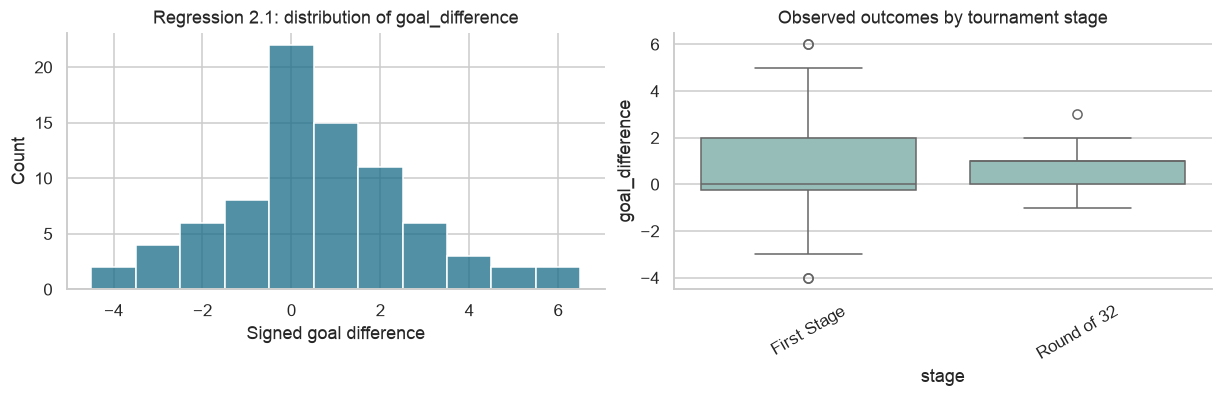

**Reading the target:** training mean 0.60, median 0.00, SD 2.10 goals; skewness 0.26. Integer outcomes limit the normal-error approximation. Stage differences combine team selection and context; they are not causal effects.

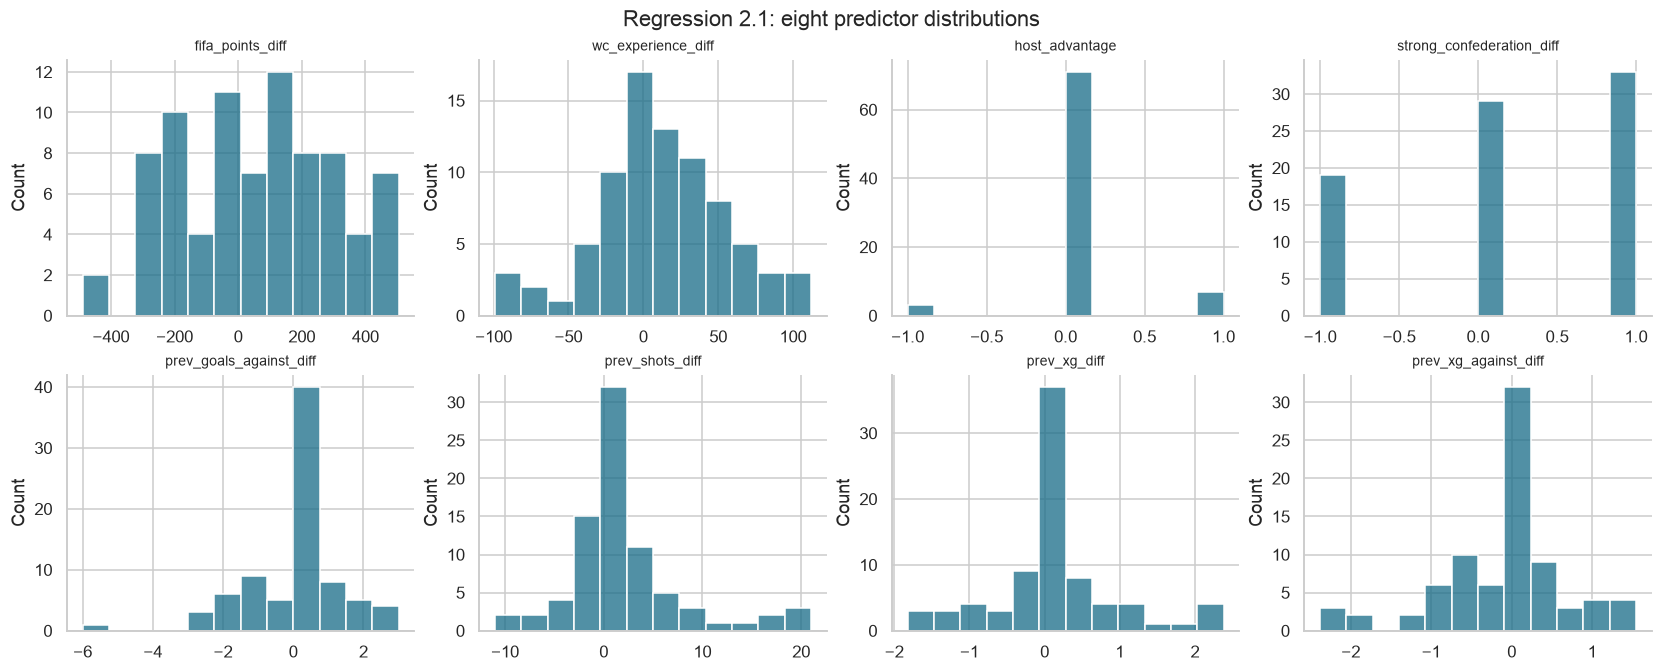

**Reading the predictors:** point masses in historical variables include the neutral first-match prior. Rare host or stage indicators can be constant in early folds. Scaling is fitted separately within each training fold; no outliers are deleted.

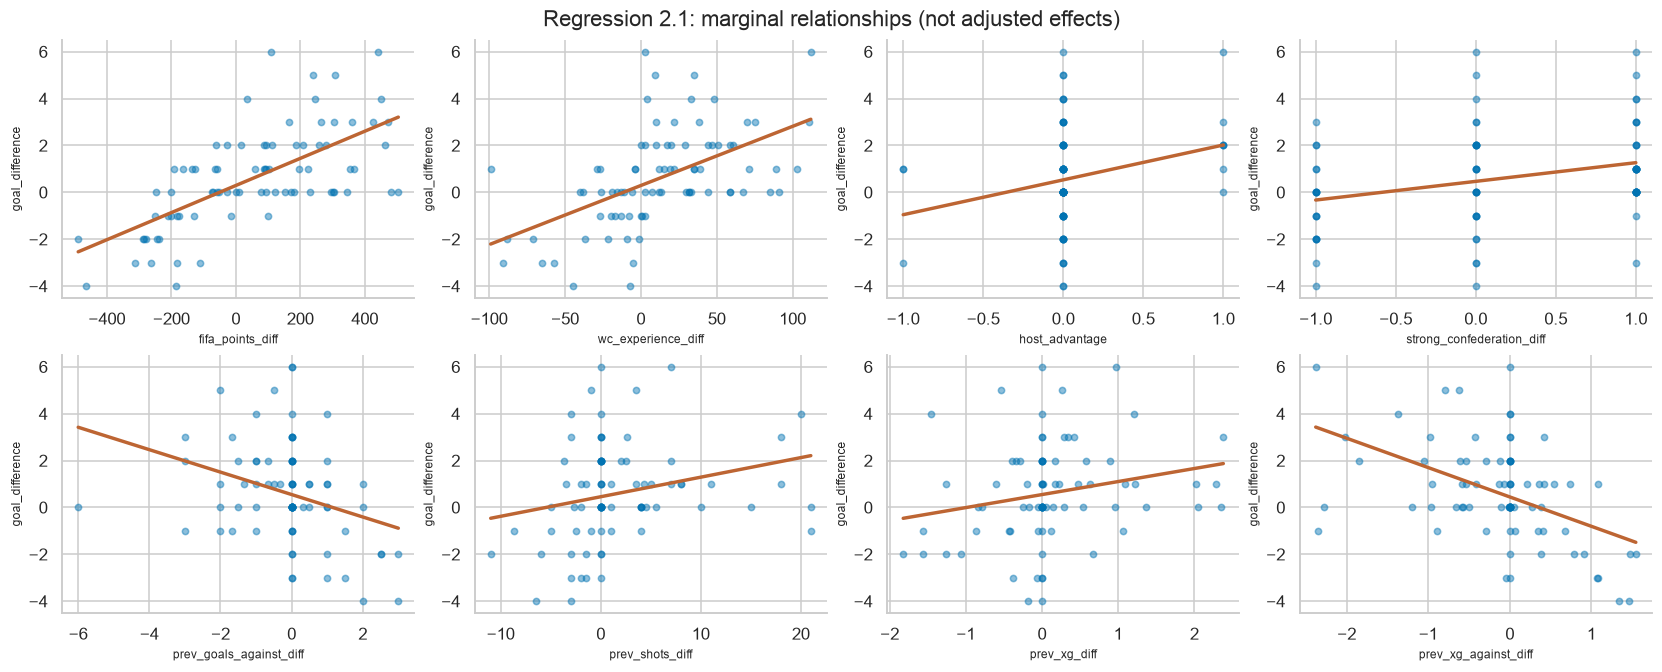

,Pearson r with target
fifa_points_diff,0.6560
wc_experience_diff,0.5330
prev_xg_against_diff,-0.4749
prev_goals_against_diff,-0.3150
strong_confederation_diff,0.2987
host_advantage,0.2477
prev_shots_diff,0.2448
prev_xg_diff,0.2179


**Marginal signal:** `fifa_points_diff` has the largest absolute training correlation (0.66). These plots diagnose relationships; they do not select features. Confounding and repeated teams can produce associations without independent predictive value.

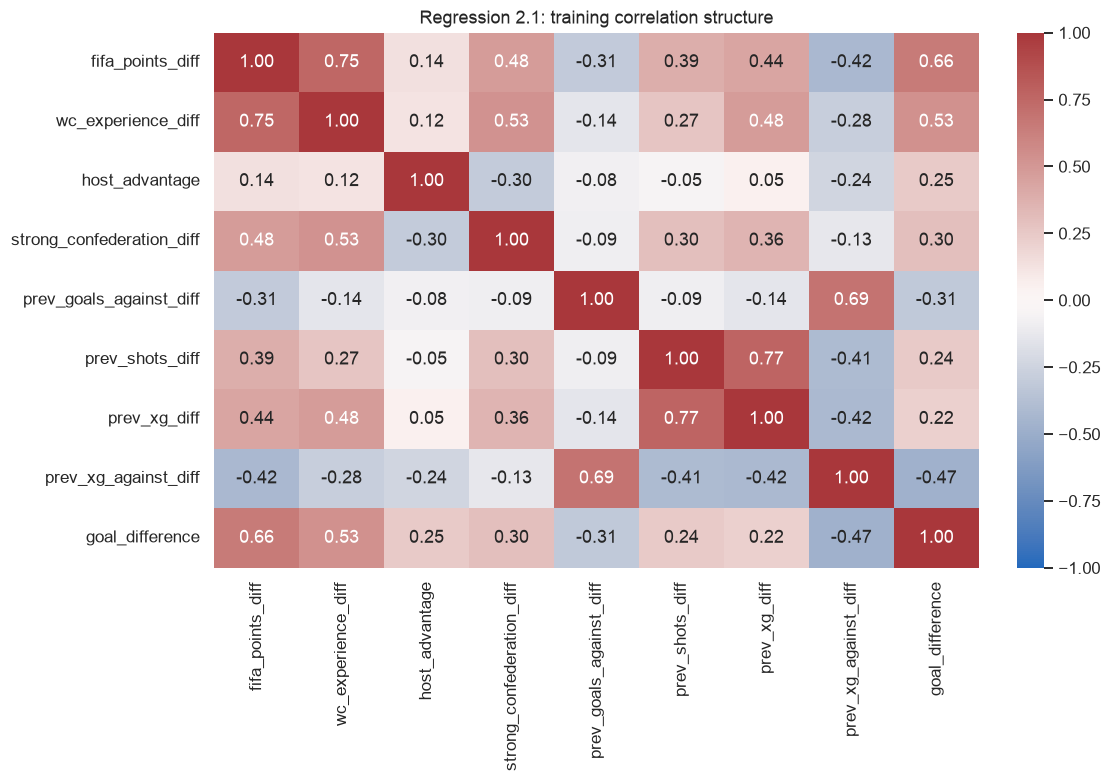

**Redundancy:** large absolute correlations indicate potentially unstable partial coefficients. VIF and regularisation below address this without automatically deleting required predictors.

,Missing,IQR flagged
fifa_points_diff,0,0
wc_experience_diff,0,2
host_advantage,0,10
strong_confederation_diff,0,0
prev_goals_against_diff,0,11
prev_shots_diff,0,7
prev_xg_diff,0,17
prev_xg_against_diff,0,8
goal_difference,0,4


,match_number,goal_difference,fifa_points_diff,wc_experience_diff,host_advantage,strong_confederation_diff,prev_goals_against_diff,prev_shots_diff,prev_xg_diff,prev_xg_against_diff
9,10,6,441,112,0,1,0.0,0.0,0.000,0.000
26,27,6,109,3,1,0,0.0,7.0,0.977,-2.380
35,36,-4,-186,-7,0,0,3.0,-3.0,0.003,1.462
63,64,-4,-466,-45,0,-1,2.0,-6.5,-0.186,1.334


**Outliers and missingness:** IQR flags are screening indicators, especially unreliable for binary predictors. Unusual scores may be legitimate football outcomes. No observation is excluded without source evidence; a training-only transformation sensitivity analysis follows.

In [8]:
eda(train21,features_21,'goal_difference','Regression 2.1')

## 8. Regression 2.1 · Baseline, competing models and optimisation
The mean-only dummy provides a minimum benchmark. Ordinary multiple linear regression is the core assignment model. Ridge stabilises correlated predictors; Lasso tests a sparse coefficient solution; Elastic Net balances sparsity and grouped shrinkage. The input dataset retains eight variables even when a penalised coefficient is zero. No nonlinear benchmark is added simply to increase the model count.

The alpha grid spans weak to strong regularisation. The same date folds apply to every model; default versus nested-tuned scores assess whether optimisation helps. Three folds do not represent three independent experiments, so SD is a measure of variability, not a confidence interval.

In [9]:
result21=experiment(train21,features_21,'goal_difference')
display(result21['folds']); display(result21['search']); display(result21['comparison'])

,Model,Fold,MAE,MSE,RMSE,NRMSE,NRMSE (%),R2,Train RMSE,Parameters,Validation matches
0,Dummy,1,1.6548,4.9606,2.2272,0.2784,27.8405,-0.2071,2.1152,{},16
1,Dummy,2,1.8368,5.4520,2.3350,0.2594,25.9439,-0.2594,2.1315,{},15
2,Dummy,3,0.9812,1.4492,1.2038,0.3010,30.0954,-0.0661,2.1640,{},8
3,Linear Regression,1,1.7596,4.6982,2.1675,0.2709,27.0941,-0.1433,1.4886,{},16
4,Linear Regression,2,0.9126,1.7212,1.3119,0.1458,14.5771,0.6024,1.5441,{},15
5,Linear Regression,3,0.7161,0.6846,0.8274,0.2069,20.6857,0.4964,1.4793,{},8
6,Ridge,1,1.6820,4.1854,2.0458,0.2557,25.5727,-0.0185,1.4909,{'model__alpha': 1.0},16
7,Ridge,2,0.9187,1.8174,1.3481,0.1498,14.9790,0.5802,1.5565,{'model__alpha': 10.0},15
8,Ridge,3,0.7230,0.8005,0.8947,0.2237,22.3675,0.4111,1.4923,{'model__alpha': 10.0},8
9,Lasso,1,1.7551,4.6685,2.1607,0.2701,27.0084,-0.1361,1.4886,{'model__alpha': 0.001},16


,Model,Search space,Best parameters,Best inner CV RMSE
0,Ridge,"{'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}",{'model__alpha': 10.0},1.2914
1,Lasso,"{'model__alpha': [0.001, 0.01, 0.1, 1.0]}",{'model__alpha': 0.1},1.2782
2,ElasticNet,"{'model__alpha': [0.001, 0.01, 0.1, 1.0], 'model__l1_ratio': [0.2, 0.5, 0.8]}","{'model__alpha': 0.1, 'model__l1_ratio': 0.8}",1.2955


,CV_MAE,CV_RMSE,CV_RMSE_SD,CV_NRMSE,CV_NRMSE_SD,CV_R2,CV_MAE_SD,CV_R2_SD,Outer_train_RMSE,Default CV RMSE
Model,,,,,,,,,,
ElasticNet,1.1053,1.4144,0.4421,0.2080,0.0315,0.3521,0.3847,0.1085,1.5776,1.3150
Ridge,1.1079,1.4295,0.5799,0.2097,0.0543,0.3243,0.5067,0.3086,1.5133,1.3995
Linear Regression,1.1294,1.4356,0.6786,0.2079,0.0626,0.3185,0.5545,0.4034,1.5040,1.4356
Lasso,1.1285,1.4663,0.6319,0.2157,0.0635,0.2787,0.5505,0.3773,1.5236,1.2782
Dummy,1.4909,1.9220,0.6243,0.2796,0.0208,-0.1775,0.4507,0.1000,2.1369,1.9220


## 9. Linear inference, VIF and diagnostic methods
The unpenalised OLS model is fitted only on the prepared training matrix. We report both conventional standard errors and match-cluster robust uncertainty. Clustering accounts for the paired rows in 2.2; it **does not** fully handle repeated teams across matches. For 2.1, one row per cluster makes this similar to a heteroscedasticity-robust calculation. P-values and intervals are exploratory and conditional on the selected specification.

Breusch–Pagan screens for changing residual variance; Q–Q plots assess tail shape. Durbin–Watson is descriptive because tournament ordering and shared teams violate a simple equally spaced time-series interpretation. Cook's distance above $4/n$ and leverage above $2p/n$ flag cases for investigation, not automatic removal. Normality is chiefly relevant to small-sample inference, rather than a prerequisite for computing predictions.

,Feature,Coefficient,Conventional SE,Cluster SE,t,p,CI low,CI high
0,const,0.6049,0.1681,0.1681,3.5987,0.0006,0.2704,0.9395
1,fifa_points_diff,0.8983,0.2890,0.2734,3.2858,0.0015,0.3542,1.4423
2,wc_experience_diff,0.4038,0.2963,0.2964,1.3623,0.1769,-0.1861,0.9937
3,host_advantage,0.2940,0.1987,0.1752,1.6775,0.0973,-0.0548,0.6427
4,strong_confederation_diff,0.1397,0.2271,0.2213,0.6313,0.5297,-0.3007,0.5800
5,prev_goals_against_diff,0.0768,0.2536,0.3146,0.2441,0.8078,-0.5493,0.7029
6,prev_shots_diff,0.2839,0.2959,0.3254,0.8726,0.3855,-0.3636,0.9314
7,prev_xg_diff,-0.6599,0.2992,0.3339,-1.9764,0.0516,-1.3244,0.0046
8,prev_xg_against_diff,-0.6190,0.2851,0.3445,-1.7967,0.0762,-1.3047,0.0666


OLS intercept: 0.6049; R²: 0.5336; adjusted R²: 0.4818
Classical overall F: 10.297774965370062 p: 1.7707622957417936e-09 | Cluster-robust F: 10.852907860127885 p: 3.187036116605447e-10
Design rank: 9 / 9 | Condition number: 4.947679038258659


,Feature,VIF
0,fifa_points_diff,2.9549
1,wc_experience_diff,3.1069
2,host_advantage,1.3967
3,strong_confederation_diff,1.8245
4,prev_goals_against_diff,2.2764
5,prev_shots_diff,3.0990
6,prev_xg_diff,3.1678
7,prev_xg_against_diff,2.8759


,Diagnostic,Value
0,Breusch–Pagan LM,8.7192
1,Breusch–Pagan p,0.3665
2,Durbin–Watson,2.0464


,match_number,Residual,Studentised residual,Leverage,Cooks distance,Flag
26,27,3.1957,2.5282,0.3019,0.3072,True
34,34,-2.4361,-1.8931,0.2765,0.1522,True
42,41,2.4060,1.8435,0.2558,0.1298,True
36,37,-2.8516,-2.1136,0.2047,0.1278,True
31,31,-2.0547,-1.5637,0.2456,0.0884,True
58,59,1.4524,1.1458,0.2980,0.0619,True
9,10,3.0023,2.0964,0.1039,0.0566,True
45,46,-1.7833,-1.3332,0.2183,0.0551,True
13,14,-2.8247,-1.9525,0.0856,0.0397,False
44,45,-1.5382,-1.1392,0.2034,0.0368,False


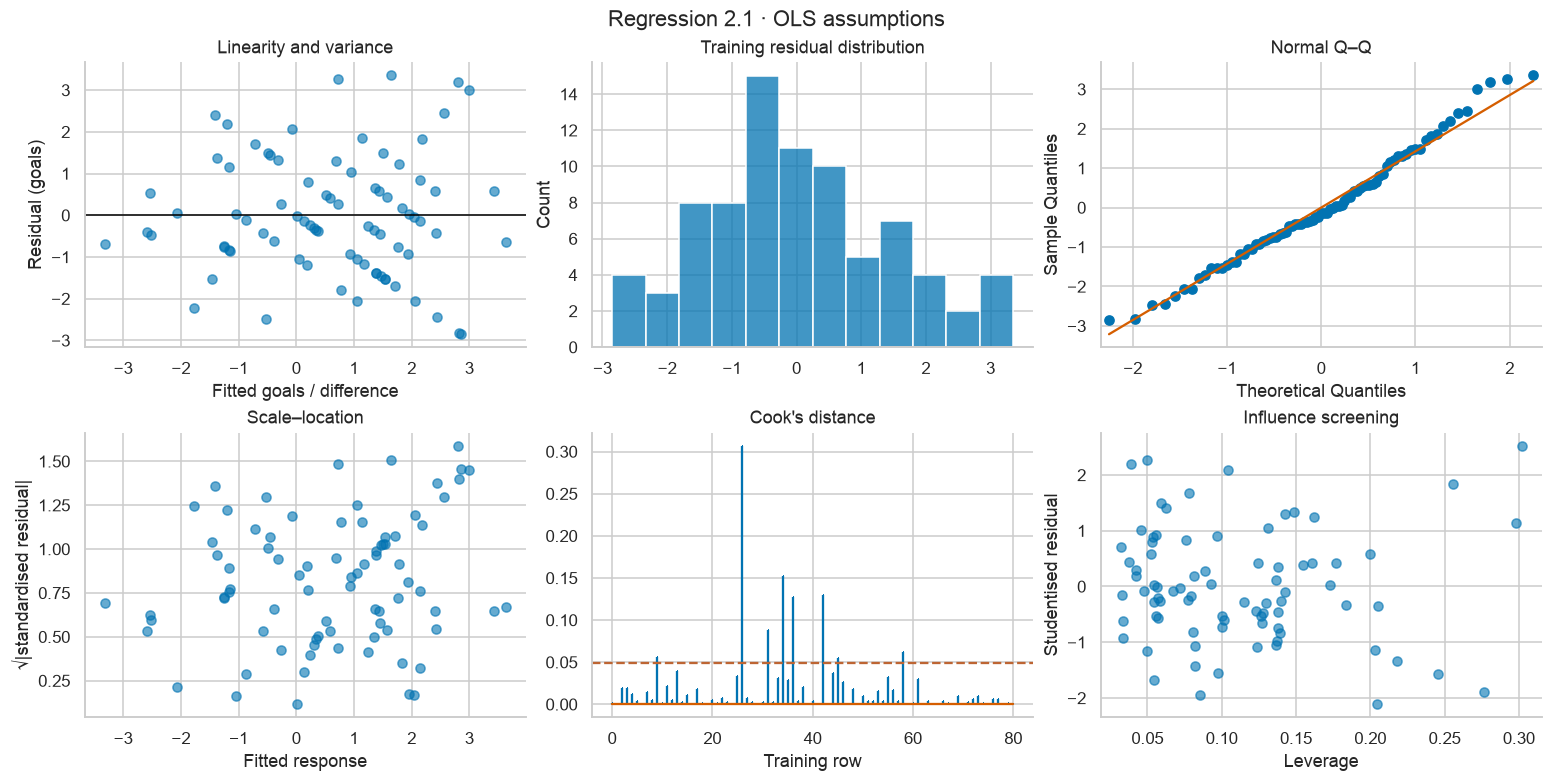

**Interpretation:** training adjusted R² is 0.482. Cluster-robust intervals exclude zero at the nominal 5% level for ['fifa_points_diff']. These are conditional associations without multiplicity correction, not proof of causal or predictive importance. VIF exceeds 5 for no predictors; related football measures are retained and regularised. Breusch–Pagan p=0.367 does not establish homoscedasticity; power is limited. 8 rows are influence flags; all are retained. Repeated teams mean independence remains questionable. Discrete targets and residual tails limit classical interval calibration.

In [10]:
def diagnose(result,label):
    train,fs,target=result['train'],result['fs'],result['target']
    prep=result['fitted']['Linear Regression'][:-1]
    z=prep.transform(train[fs])
    design=sm.add_constant(pd.DataFrame(z,columns=fs),has_constant='add')
    y=train[target].to_numpy()
    ols=sm.OLS(y,design).fit()
    robust=ols.get_robustcov_results(cov_type='cluster',groups=train.match_number.to_numpy(),use_t=True)
    ci=robust.conf_int()
    table=pd.DataFrame({'Feature':design.columns,'Coefficient':ols.params.to_numpy(),
                        'Conventional SE':ols.bse.to_numpy(),'Cluster SE':robust.bse,
                        't':robust.tvalues,'p':robust.pvalues,'CI low':ci[:,0],'CI high':ci[:,1]})
    display(table)
    print(f'OLS intercept: {ols.params.iloc[0]:.4f}; R²: {ols.rsquared:.4f}; adjusted R²: {ols.rsquared_adj:.4f}')
    print('Classical overall F:',ols.fvalue,'p:',ols.f_pvalue,
          '| Cluster-robust F:',robust.fvalue,'p:',robust.f_pvalue)
    print('Design rank:',np.linalg.matrix_rank(design),'/',design.shape[1], '| Condition number:',ols.condition_number)
    vif=[]
    for j,f in enumerate(fs,1):
        if np.std(z[:,j-1])==0: value=np.nan
        else: value=variance_inflation_factor(design.to_numpy(),j)
        vif.append([f,value])
    vif=pd.DataFrame(vif,columns=['Feature','VIF']); display(vif)
    bp=het_breuschpagan(ols.resid,design)
    display(pd.DataFrame({'Diagnostic':['Breusch–Pagan LM','Breusch–Pagan p','Durbin–Watson'],
                          'Value':[bp[0],bp[1],durbin_watson(ols.resid)]}))
    infl=ols.get_influence()
    influence=pd.DataFrame({'match_number':train.match_number.to_numpy(),
                            'Residual':ols.resid,'Studentised residual':infl.resid_studentized_internal,
                            'Leverage':infl.hat_matrix_diag,'Cooks distance':infl.cooks_distance[0]})
    influence['Flag']=(influence['Cooks distance']>4/len(train)) | (influence.Leverage>2*design.shape[1]/len(train))
    display(influence.sort_values('Cooks distance',ascending=False).head(10))
    fig,axes=plt.subplots(2,3,figsize=(14,7))
    axes[0,0].scatter(ols.fittedvalues,ols.resid,alpha=.6); axes[0,0].axhline(0,color='black',lw=1)
    axes[0,0].set(xlabel='Fitted goals / difference',ylabel='Residual (goals)',title='Linearity and variance')
    sns.histplot(ols.resid,bins=12,ax=axes[0,1]); axes[0,1].set_title('Training residual distribution')
    sm.qqplot(ols.resid,line='s',ax=axes[0,2]); axes[0,2].set_title('Normal Q–Q')
    axes[1,0].scatter(ols.fittedvalues,np.sqrt(np.abs(infl.resid_studentized_internal)),alpha=.6)
    axes[1,0].set(xlabel='Fitted response',ylabel='√|standardised residual|',title='Scale–location')
    axes[1,1].stem(np.arange(len(train)),influence['Cooks distance'],markerfmt=',')
    axes[1,1].axhline(4/len(train),color='#bd6533',ls='--'); axes[1,1].set(xlabel='Training row',title="Cook's distance")
    axes[1,2].scatter(influence.Leverage,influence['Studentised residual'],alpha=.6)
    axes[1,2].set(xlabel='Leverage',ylabel='Studentised residual',title='Influence screening')
    fig.suptitle(label+' · OLS assumptions'); plt.show()
    significant=table.loc[table.Feature.ne('const') & table.p.lt(.05),'Feature'].tolist()
    high=vif.loc[vif.VIF.gt(5),'Feature'].tolist()
    display(Markdown(f"**Interpretation:** training adjusted R² is {ols.rsquared_adj:.3f}. "
                    f"Cluster-robust intervals exclude zero at the nominal 5% level for {significant or 'no predictors'}. "
                    'These are conditional associations without multiplicity correction, not proof of causal or predictive importance. '
                    f"VIF exceeds 5 for {high or 'no predictors'}; related football measures are retained and regularised. "
                    f"Breusch–Pagan p={bp[1]:.3f} "
                    + ('suggests nonconstant variance. ' if bp[1]<.05 else 'does not establish homoscedasticity; power is limited. ')
                    + f"{int(influence.Flag.sum())} rows are influence flags; all are retained. "
                    'Repeated teams mean independence remains questionable. Discrete targets and residual tails limit classical interval calibration.'))
    result.update(ols=ols,robust=robust,inference=table,vif=vif,influence=influence,bp_p=bp[1])

diagnose(result21,'Regression 2.1')

## 10. Regression 2.1 · Eight-variable transformation sensitivity
Several form variables have long tails. A signed square root, $\operatorname{sign}(x)\sqrt{|x|}$, is a monotone transformation of each existing predictor that compresses those tails, so there remain exactly eight explanatory variables. It has no fitted parameter, so it behaves the same on later matches as on the training window, and it is applied inside each fold before scaling. The comparison uses fixed OLS and fixed-alpha Ridge on identical training CV folds. This is a sensitivity analysis, not a late opportunity to change the locked model family or inspect the test set. No interaction expansion is used because it would alter the eight-variable design.


In [11]:
def sensitivity(result):
    tr,fs,target=result['train'],result['fs'],result['target']
    rows=[]; details=[]
    for estimator_name,estimator in [('OLS',LinearRegression()),('Ridge alpha=1',Ridge(alpha=1.))]:
        for transform in [False,True]:
            specification=('Signed √ + ' if transform else 'Scaled ')+estimator_name
            scores=[]
            for fold,(past,future) in enumerate(temporal_folds(tr),1):
                pipe=pipeline(clone(estimator),transform=transform)
                pipe.fit(tr.iloc[past][fs],tr.iloc[past][target])
                pred=pipe.predict(tr.iloc[future][fs])
                score=metrics(tr.iloc[future][target],pred)
                design=sm.add_constant(pipe[:-1].transform(tr.iloc[past][fs]),has_constant='add')
                details.append({'Specification':specification,'Fold':fold,'RMSE':score['RMSE'],
                                'Design rank':np.linalg.matrix_rank(design),
                                'Design columns':design.shape[1],
                                'Condition number':np.linalg.cond(design),
                                'Max absolute prediction':np.abs(pred).max(),
                                'Max absolute transformed validation input':np.abs(pipe[:-1].transform(tr.iloc[future][fs])).max()})
                scores.append(score)
            scores=pd.DataFrame(scores)
            rows.append({'Specification':specification,'CV RMSE':scores.RMSE.mean(),
                         'CV MAE':scores.MAE.mean(),'RMSE SD':scores.RMSE.std()})
    table=pd.DataFrame(rows);display(table)
    details=pd.DataFrame(details);display(details)
    delta=table.iloc[3]['CV RMSE']-table.iloc[2]['CV RMSE']
    display(Markdown(f'**Robustness finding:** for fixed-alpha Ridge, the transformation changes mean CV RMSE by {delta:+.3f} goals '
                    f'(negative favours transformation), against a fold SD of {table.iloc[2]["RMSE SD"]:.3f}. '
                    'This is a training-only comparison with all rows and eight inputs retained. '
                    'A change that is small relative to the fold SD gives no reason to depart from the untransformed specification, '
                    'and this exercise does not change the core model selection rule.'))
    result['sensitivity']=table
    result['sensitivity_folds']=details
sensitivity(result21)

,Specification,CV RMSE,CV MAE,RMSE SD
0,Scaled OLS,1.4356,1.1294,0.6786
1,Signed √ + OLS,1.4703,1.1366,0.3992
2,Scaled Ridge alpha=1,1.3995,1.1037,0.6094
3,Signed √ + Ridge alpha=1,1.4424,1.1124,0.3540


,Specification,Fold,RMSE,Design rank,Design columns,Condition number,Max absolute prediction,Max absolute transformed validation input
0,Scaled OLS,1,2.1675,9,9,5.2263,3.8633,3.3853
1,Scaled OLS,2,1.3119,9,9,4.9707,2.8168,2.9292
2,Scaled OLS,3,0.8274,9,9,5.0569,2.2431,2.7499
3,Signed √ + OLS,1,1.9239,9,9,5.9646,3.7310,3.2660
4,Signed √ + OLS,2,1.3142,9,9,5.7411,2.4479,2.9292
5,Signed √ + OLS,3,1.1728,9,9,5.3161,2.5136,2.7499
6,Scaled Ridge alpha=1,1,2.0458,9,9,5.2263,3.7213,3.3853
7,Scaled Ridge alpha=1,2,1.3171,9,9,4.9707,2.7652,2.9292
8,Scaled Ridge alpha=1,3,0.8354,9,9,5.0569,2.2214,2.7499
9,Signed √ + Ridge alpha=1,1,1.8400,9,9,5.9646,3.6199,3.2660


**Robustness finding:** for fixed-alpha Ridge, the transformation changes mean CV RMSE by +0.043 goals (negative favours transformation), against a fold SD of 0.609. This is a training-only comparison with all rows and eight inputs retained. A change that is small relative to the fold SD gives no reason to depart from the untransformed specification, and this exercise does not change the core model selection rule.

## 11. Regression 2.1 · Selection locked before final testing
The following chart compares expanding-window fold scores. The best mean outer-CV model is the primary prediction recommendation, even if it is the dummy. The best linear family is separately identified to satisfy the required regression analysis. Neither is selected using the final test scores.

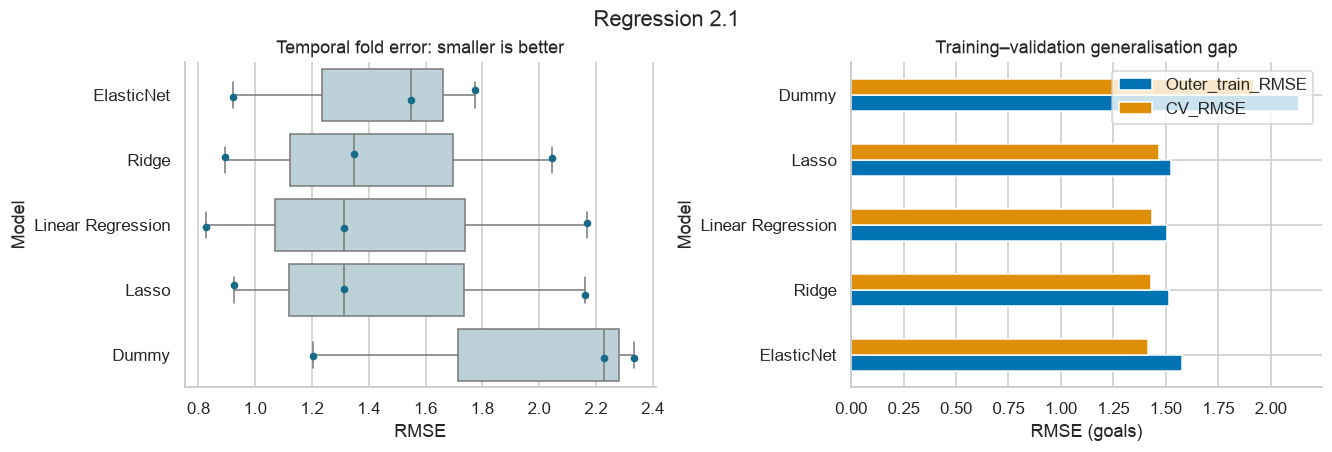

**Locked selection:** ElasticNet has the lowest nested/outer mean RMSE (1.414 goals), 26.4% below the dummy. The selected linear family is **ElasticNet**. Fold SD is 0.442; differences should be judged against this variation and the small sample. Large training–validation gaps indicate instability; strong training fit alone is not evidence of useful forecasts.

In [12]:
def lock_selection(result,label):
    comp=result['comparison']
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    order=list(comp.index)
    sns.boxplot(data=result['folds'],x='RMSE',y='Model',order=order,ax=axes[0],color='#b7d4dc')
    sns.stripplot(data=result['folds'],x='RMSE',y='Model',order=order,ax=axes[0],color='#176b87',size=5)
    axes[0].set_title('Temporal fold error: smaller is better')
    comp[['Outer_train_RMSE','CV_RMSE']].plot.barh(ax=axes[1])
    axes[1].set(xlabel='RMSE (goals)',title='Training–validation generalisation gap')
    fig.suptitle(label);plt.show()
    winner=result['winner']; linear=result['best_linear']
    baseline=comp.loc['Dummy','CV_RMSE']; selected=comp.loc[winner,'CV_RMSE']
    display(Markdown(f'**Locked selection:** {winner} has the lowest nested/outer mean RMSE ({selected:.3f} goals), '
                    f'{100*(baseline-selected)/baseline:.1f}% below the dummy. '
                    f'The selected linear family is **{linear}**. Fold SD is {comp.loc[winner,"CV_RMSE_SD"]:.3f}; '
                    'differences should be judged against this variation and the small sample. '
                    'Large training–validation gaps indicate instability; strong training fit alone is not evidence of useful forecasts.'))
    result['locked']=True
lock_selection(result21,'Regression 2.1')

## 12. Regression 2.2 · Dataset, EDA and preparation
Each of the same 104 matches contributes two rows: one per team. Opponent statistics are matched by `(match_number, opponent)` to the other row, after chronological historical features have been computed. The earlier validation table verifies 208 distinct team–match keys and eight predictors. Both teams stay together in every fold and test split. Effective information is less than 208 independent observations.

Ranks are treated as numeric ordered strength proxies; equal rank gaps need not have equal football meaning, a limitation of this linear specification. Confederation membership and host status are encoded 0/1; possession is a fraction. Imputation and scaling remain training-only.

### Regression 2.2: training data only

,count,mean,std,min,25%,50%,75%,max,variance,IQR,skewness
team_fifa_rank,162.0,31.2778,23.0859,1.0000,13.0000,27.0,45.7500,85.0000,532.9596,32.7500,0.7061
opponent_fifa_rank,162.0,31.2778,23.0859,1.0000,13.0000,27.0,45.7500,85.0000,532.9596,32.7500,0.7061
team_strong_confederation,162.0,0.4691,0.5006,0.0000,0.0000,0.0,1.0000,1.0000,0.2506,1.0000,0.1249
opponent_strong_confederation,162.0,0.4691,0.5006,0.0000,0.0000,0.0,1.0000,1.0000,0.2506,1.0000,0.1249
team_prev_possession,162.0,0.0032,0.0917,-0.2147,-0.0200,0.0,0.0524,0.2354,0.0084,0.0724,-0.2344
team_prev_linebreaks,162.0,0.7328,24.1203,-56.3261,-10.2108,0.0,13.6448,77.1967,581.7907,23.8556,0.3817
team_is_host,162.0,0.0617,0.2414,0.0000,0.0000,0.0,0.0000,1.0000,0.0583,0.0000,3.6764
opponent_prev_xg_against,162.0,-0.0354,0.6302,-1.1733,-0.4528,0.0,0.1757,2.9149,0.3971,0.6285,1.5157
goals_scored,162.0,1.4753,1.4151,0.0000,0.0000,1.0,2.0000,7.0000,2.0025,2.0000,1.1893


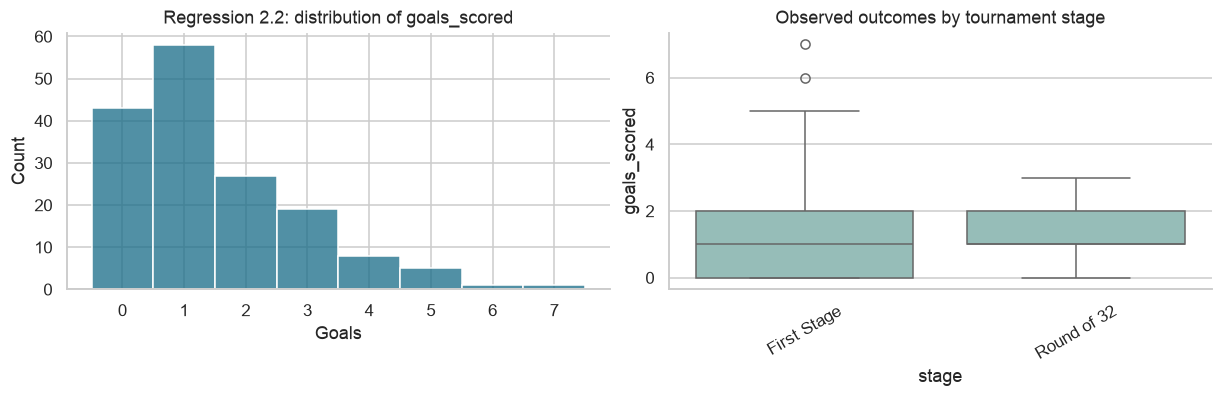

**Reading the target:** training mean 1.48, median 1.00, SD 1.42 goals; skewness 1.19. Integer outcomes limit the normal-error approximation. Stage differences combine team selection and context; they are not causal effects.

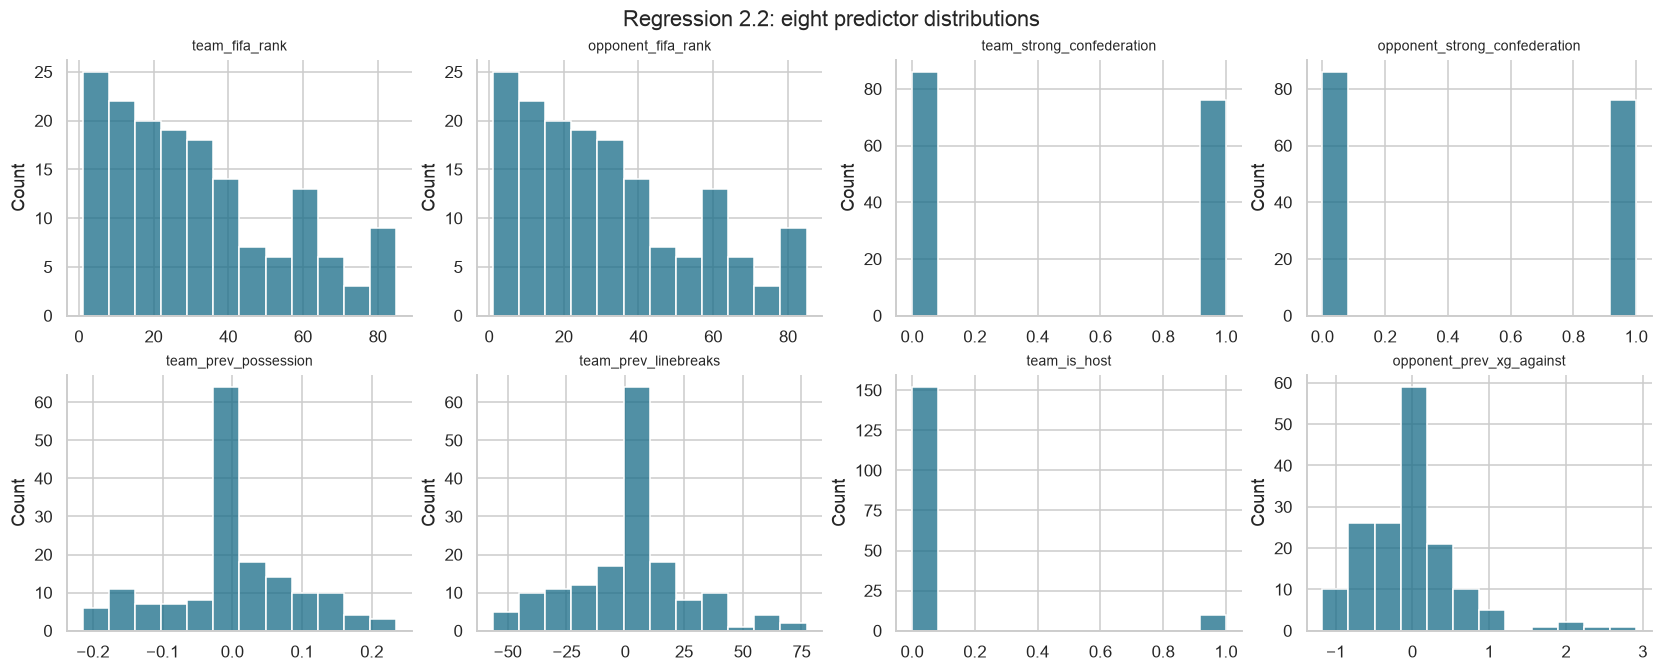

**Reading the predictors:** point masses in historical variables include the neutral first-match prior. Rare host or stage indicators can be constant in early folds. Scaling is fitted separately within each training fold; no outliers are deleted.

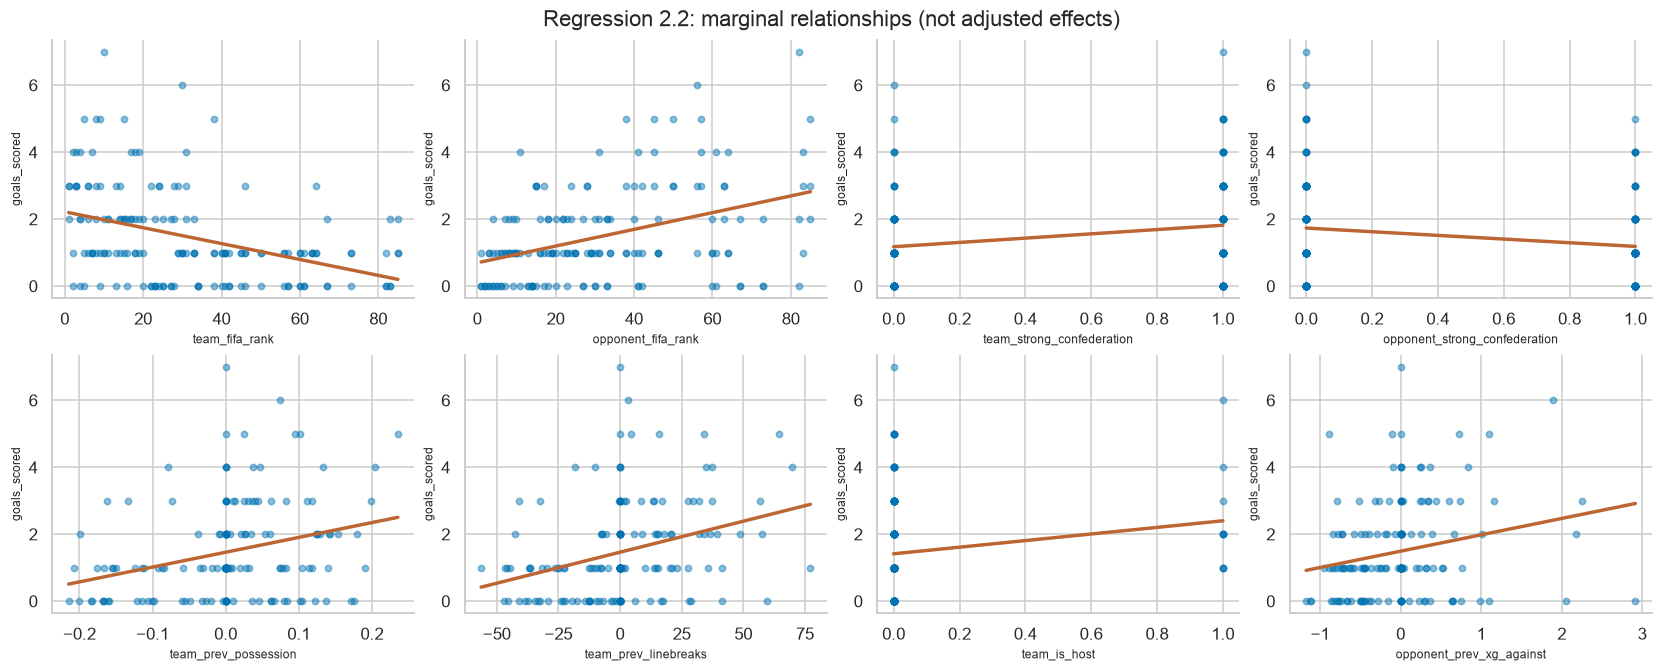

,Pearson r with target
opponent_fifa_rank,0.4074
team_fifa_rank,-0.3872
team_prev_linebreaks,0.3157
team_prev_possession,0.2871
team_strong_confederation,0.2269
opponent_prev_xg_against,0.2176
opponent_strong_confederation,-0.1940
team_is_host,0.1681


**Marginal signal:** `opponent_fifa_rank` has the largest absolute training correlation (0.41). These plots diagnose relationships; they do not select features. Confounding and repeated teams can produce associations without independent predictive value.

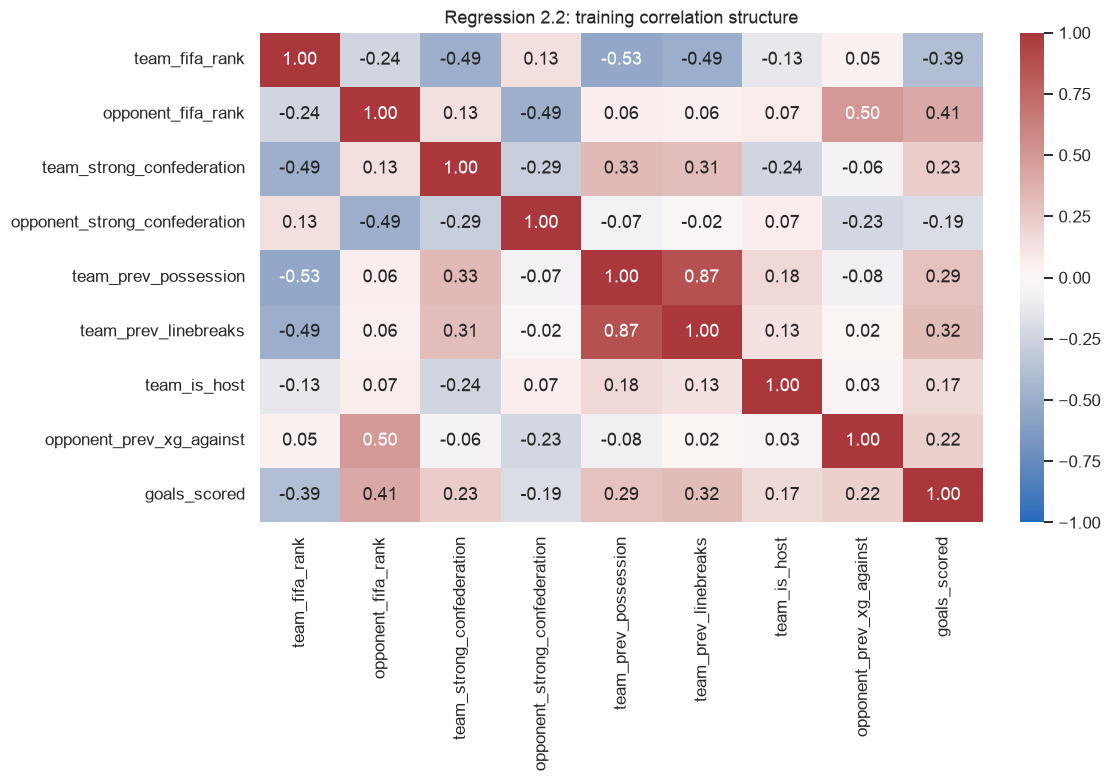

**Redundancy:** large absolute correlations indicate potentially unstable partial coefficients. VIF and regularisation below address this without automatically deleting required predictors.

,Missing,IQR flagged
team_fifa_rank,0,0
opponent_fifa_rank,0,0
team_strong_confederation,0,0
opponent_strong_confederation,0,0
team_prev_possession,0,25
team_prev_linebreaks,0,9
team_is_host,0,10
opponent_prev_xg_against,0,6
goals_scored,0,2


,match_number,goals_scored,team_fifa_rank,opponent_fifa_rank,team_strong_confederation,opponent_strong_confederation,team_prev_possession,team_prev_linebreaks,team_is_host,opponent_prev_xg_against
18,10,7,10,82,1,0,0.000,0.0000,0,0.0000
52,27,6,30,56,0,0,0.074,3.2955,1,1.8874


**Outliers and missingness:** IQR flags are screening indicators, especially unreliable for binary predictors. Unusual scores may be legitimate football outcomes. No observation is excluded without source evidence; a training-only transformation sensitivity analysis follows.

In [13]:
eda(train22,features_22,'goals_scored','Regression 2.2')

## 13. Regression 2.2 · Baseline, competing algorithms and nested optimisation
The same linear model families, hyperparameter grids and temporal match boundaries are used. This enables comparison of procedures without treating the two targets as interchangeable. Continuous predictions are not rounded or clipped for scoring; negative team-goal predictions are explicitly counted at final evaluation. A count model could be a future extension, but it is not a substitute for the required multiple linear regression.

In [14]:
result22=experiment(train22,features_22,'goals_scored')
display(result22['folds']); display(result22['search']); display(result22['comparison'])

,Model,Fold,MAE,MSE,RMSE,NRMSE,NRMSE (%),R2,Train RMSE,Parameters,Validation matches
0,Dummy,1,1.0938,1.6875,1.2990,0.2598,25.9808,-0.0023,1.5000,{},16
1,Dummy,2,1.2621,2.2491,1.4997,0.2999,29.9943,-0.0001,1.4472,{},15
2,Dummy,3,0.7474,0.7479,0.8648,0.2883,28.8262,-0.0024,1.4582,{},8
3,Linear Regression,1,0.9081,1.2755,1.1294,0.2259,22.5880,0.2424,1.2737,{},16
4,Linear Regression,2,1.0183,1.4860,1.2190,0.2438,24.3802,0.3392,1.2229,{},15
5,Linear Regression,3,0.6109,0.5397,0.7346,0.2449,24.4870,0.2767,1.2193,{},8
6,Ridge,1,0.8790,1.1839,1.0881,0.2176,21.7612,0.2968,1.3220,{'model__alpha': 100.0},16
7,Ridge,2,1.0305,1.5819,1.2577,0.2515,25.1549,0.2966,1.2504,{'model__alpha': 100.0},15
8,Ridge,3,0.6128,0.5352,0.7316,0.2439,24.3857,0.2827,1.2204,{'model__alpha': 10.0},8
9,Lasso,1,1.0938,1.6875,1.2990,0.2598,25.9808,-0.0023,1.5000,{'model__alpha': 1.0},16


,Model,Search space,Best parameters,Best inner CV RMSE
0,Ridge,"{'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}",{'model__alpha': 10.0},1.0194
1,Lasso,"{'model__alpha': [0.001, 0.01, 0.1, 1.0]}",{'model__alpha': 0.01},1.0255
2,ElasticNet,"{'model__alpha': [0.001, 0.01, 0.1, 1.0], 'model__l1_ratio': [0.2, 0.5, 0.8]}","{'model__alpha': 0.1, 'model__l1_ratio': 0.2}",1.0171


,CV_MAE,CV_RMSE,CV_RMSE_SD,CV_NRMSE,CV_NRMSE_SD,CV_R2,CV_MAE_SD,CV_R2_SD,Outer_train_RMSE,Default CV RMSE
Model,,,,,,,,,,
Ridge,0.8407,1.0258,0.2686,0.2377,0.0178,0.2920,0.2115,0.0081,1.2643,1.0265
Linear Regression,0.8458,1.0277,0.2577,0.2382,0.0107,0.2861,0.2107,0.0491,1.2386,1.0277
ElasticNet,0.8893,1.0764,0.3159,0.2475,0.0177,0.2304,0.2486,0.0566,1.3002,1.0171
Lasso,0.9914,1.1773,0.3976,0.2680,0.0287,0.0925,0.3338,0.1623,1.3891,1.0258
Dummy,1.0344,1.2212,0.3245,0.2827,0.0206,-0.0016,0.2624,0.0013,1.4685,1.2212


## 14. Regression 2.2 · Statistical inference and assumptions
The paired team outcomes in a match share conditions. Match-cluster robust standard errors address that pairing, while temporal validation addresses ordering. Neither makes repeat observations of the same team independent. Report coefficient intervals as exploratory associations rather than definitive tests of football mechanisms.

,Feature,Coefficient,Conventional SE,Cluster SE,t,p,CI low,CI high
0,const,1.4753,0.0954,0.1019,14.4831,4.5635e-24,1.2726,1.6780
1,team_fifa_rank,-0.2652,0.1297,0.1179,-2.2502,2.7185e-02,-0.4998,-0.0307
2,opponent_fifa_rank,0.4293,0.1287,0.1605,2.6746,9.0701e-03,0.1099,0.7488
3,team_strong_confederation,0.1224,0.1225,0.1179,1.0382,3.0230e-01,-0.1122,0.3570
4,opponent_strong_confederation,0.0177,0.1147,0.1125,0.1572,8.7547e-01,-0.2063,0.2416
5,team_prev_possession,-0.0963,0.2062,0.2030,-0.4741,6.3669e-01,-0.5003,0.3078
6,team_prev_linebreaks,0.3118,0.1998,0.1818,1.7151,9.0199e-02,-0.0500,0.6736
7,team_is_host,0.1746,0.1047,0.1171,1.4905,1.4003e-01,-0.0585,0.4076
8,opponent_prev_xg_against,0.0994,0.1154,0.1806,0.5505,5.8353e-01,-0.2600,0.4588


OLS intercept: 1.4753; R²: 0.3003; adjusted R²: 0.2638
Classical overall F: 8.209843078760697 p: 3.2555095918348575e-09 | Cluster-robust F: 9.077174281519069 p: 8.679740822256753e-09
Design rank: 9 / 9 | Condition number: 4.723258638113995


,Feature,VIF
0,team_fifa_rank,1.8488
1,opponent_fifa_rank,1.8192
2,team_strong_confederation,1.6483
3,opponent_strong_confederation,1.4456
4,team_prev_possession,4.6712
5,team_prev_linebreaks,4.3855
6,team_is_host,1.2039
7,opponent_prev_xg_against,1.4637


,Diagnostic,Value
0,Breusch–Pagan LM,29.7203
1,Breusch–Pagan p,0.0002
2,Durbin–Watson,1.8205


,match_number,Residual,Studentised residual,Leverage,Cooks distance,Flag
52,27,3.2368,2.9434,0.1798,0.2110,True
68,34,-3.2265,-2.8972,0.1588,0.1760,True
18,10,4.2649,3.6045,0.0504,0.0766,True
66,35,3.2090,2.7265,0.0604,0.0531,True
4,3,-1.6844,-1.4921,0.1357,0.0388,True
90,46,-1.3569,-1.2286,0.1727,0.0350,True
122,62,2.6804,2.2713,0.0553,0.0336,True
62,31,-2.3241,-1.9829,0.0682,0.0320,True
88,45,-2.3567,-2.0081,0.0658,0.0316,True
6,4,1.5949,1.3938,0.1119,0.0272,True


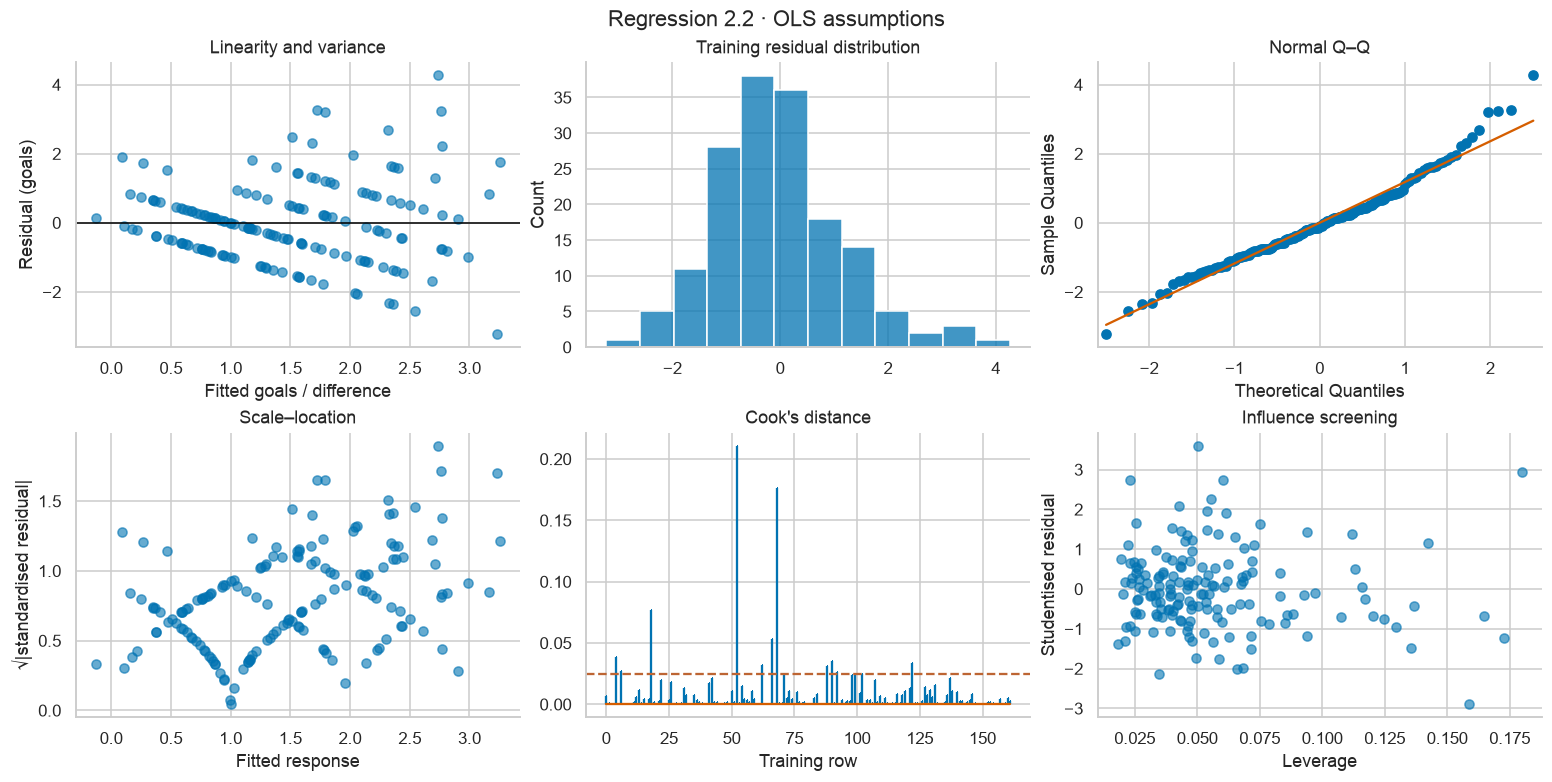

**Interpretation:** training adjusted R² is 0.264. Cluster-robust intervals exclude zero at the nominal 5% level for ['team_fifa_rank', 'opponent_fifa_rank']. These are conditional associations without multiplicity correction, not proof of causal or predictive importance. VIF exceeds 5 for no predictors; related football measures are retained and regularised. Breusch–Pagan p=0.000 suggests nonconstant variance. 20 rows are influence flags; all are retained. Repeated teams mean independence remains questionable. Discrete targets and residual tails limit classical interval calibration.

In [15]:
diagnose(result22,'Regression 2.2')

## 15. Regression 2.2 · Sensitivity and selection lock
The same eight-input signed-square-root sensitivity is evaluated on training folds, and the core family selection is locked using outer CV.

,Specification,CV RMSE,CV MAE,RMSE SD
0,Scaled OLS,1.0277,0.8458,0.2577
1,Signed √ + OLS,1.0292,0.8428,0.2266
2,Scaled Ridge alpha=1,1.0265,0.8450,0.2574
3,Signed √ + Ridge alpha=1,1.0274,0.8418,0.2266


,Specification,Fold,RMSE,Design rank,Design columns,Condition number,Max absolute prediction,Max absolute transformed validation input
0,Scaled OLS,1,1.1294,9,9,5.2527,2.8430,3.9960
1,Scaled OLS,2,1.2190,9,9,4.6068,3.1779,3.6742
2,Scaled OLS,3,0.7346,9,9,4.7524,2.4791,3.9016
3,Signed √ + OLS,1,1.1359,9,9,4.4314,2.9984,3.6056
4,Signed √ + OLS,2,1.1828,9,9,3.6102,3.0643,3.6742
5,Signed √ + OLS,3,0.7690,9,9,3.8699,2.6836,3.9016
6,Scaled Ridge alpha=1,1,1.1262,9,9,5.2527,2.8254,3.9960
7,Scaled Ridge alpha=1,2,1.2192,9,9,4.6068,3.1653,3.6742
8,Scaled Ridge alpha=1,3,0.7342,9,9,4.7524,2.4678,3.9016
9,Signed √ + Ridge alpha=1,1,1.1316,9,9,4.4314,2.9801,3.6056


**Robustness finding:** for fixed-alpha Ridge, the transformation changes mean CV RMSE by +0.001 goals (negative favours transformation), against a fold SD of 0.257. This is a training-only comparison with all rows and eight inputs retained. A change that is small relative to the fold SD gives no reason to depart from the untransformed specification, and this exercise does not change the core model selection rule.

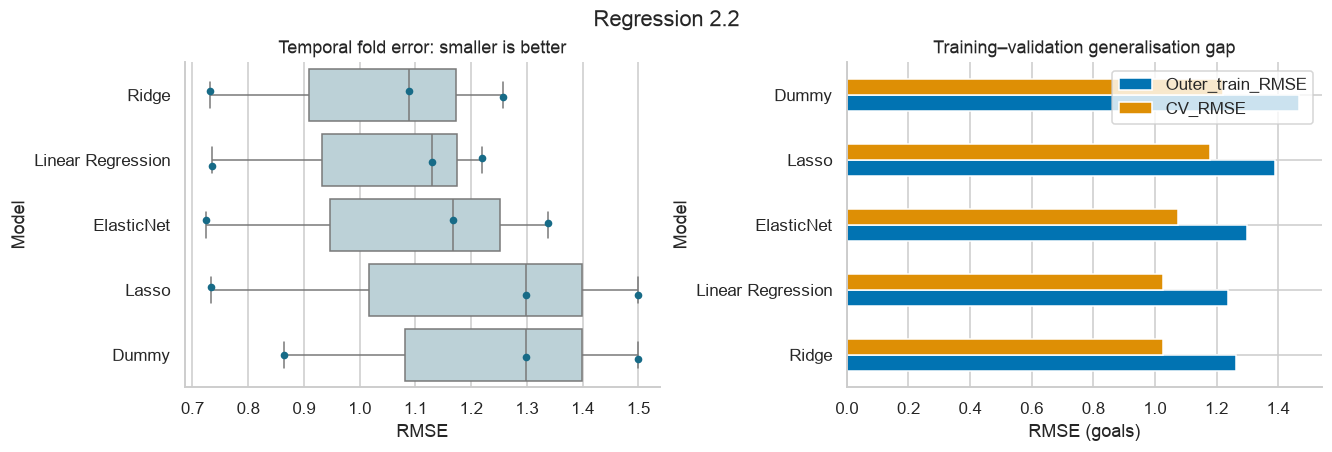

**Locked selection:** Ridge has the lowest nested/outer mean RMSE (1.026 goals), 16.0% below the dummy. The selected linear family is **Ridge**. Fold SD is 0.269; differences should be judged against this variation and the small sample. Large training–validation gaps indicate instability; strong training fit alone is not evidence of useful forecasts.

In [16]:
sensitivity(result22)
lock_selection(result22,'Regression 2.2')

## 16. Final evaluation of both tasks · Test set opened once
All model families, preprocessing choices, search spaces and recommendation rules are now fixed. Each fitted candidate is evaluated once in this final stage for transparent comparison. Only the previously locked recommendation drives the conclusion; a test leader is not used to reselect the model.

Test residuals are observed minus predicted. Actual-versus-predicted plots use an equality line; residual plots examine remaining bias. Paired **match-level** bootstrap intervals quantify test MAE and improvement over the dummy while keeping 2.2's two sides together. They remain conditional on this test set, ignore cross-match team dependence, and are not model prediction intervals.

,CV_MAE,CV_RMSE,CV_RMSE_SD,CV_NRMSE,CV_NRMSE_SD,CV_R2,CV_MAE_SD,CV_R2_SD,Outer_train_RMSE,Default CV RMSE,Test MAE,Test MSE,Test RMSE,Test NRMSE,Test NRMSE (%),Test R2,Full train RMSE
Model,,,,,,,,,,,,,,,,,
ElasticNet,1.1053,1.4144,0.4421,0.2080,0.0315,0.3521,0.3847,0.1085,1.5776,1.3150,1.1576,2.2589,1.5030,0.2505,25.0495,0.1747,1.4579
Ridge,1.1079,1.4295,0.5799,0.2097,0.0543,0.3243,0.5067,0.3086,1.5133,1.3995,1.1516,2.2254,1.4918,0.2486,24.8628,0.1870,1.4385
Linear Regression,1.1294,1.4356,0.6786,0.2079,0.0626,0.3185,0.5545,0.4034,1.5040,1.4356,1.1761,2.2449,1.4983,0.2497,24.9714,0.1799,1.4264
Lasso,1.1285,1.4663,0.6319,0.2157,0.0635,0.2787,0.5505,0.3773,1.5236,1.2782,1.1534,2.2337,1.4945,0.2491,24.9090,0.1840,1.4643
Dummy,1.4909,1.9220,0.6243,0.2796,0.0208,-0.1775,0.4507,0.1000,2.1369,1.9220,1.4611,3.0525,1.7471,0.2912,29.1189,-0.1152,2.0886


,match_number,date,team1,team2,Actual,Predicted,Residual
81,81,2026-07-02,USA,Bosnia and Herzegovina,2,2.1310,-0.1310
82,83,2026-07-02,Portugal,Croatia,1,0.7572,0.2428
83,84,2026-07-02,Spain,Austria,3,2.1169,0.8831
84,85,2026-07-03,Switzerland,Algeria,2,0.6376,1.3624
85,86,2026-07-03,Argentina,Cabo Verde,1,2.9615,-1.9615
86,88,2026-07-03,Australia,Egypt,0,0.6329,-0.6329
87,87,2026-07-04,Colombia,Ghana,1,1.5856,-0.5856
88,89,2026-07-04,Paraguay,France,-1,-1.4983,0.4983
89,90,2026-07-04,Canada,Morocco,-3,-0.8159,-2.1841
90,91,2026-07-05,Brazil,Norway,-1,2.1204,-3.1204


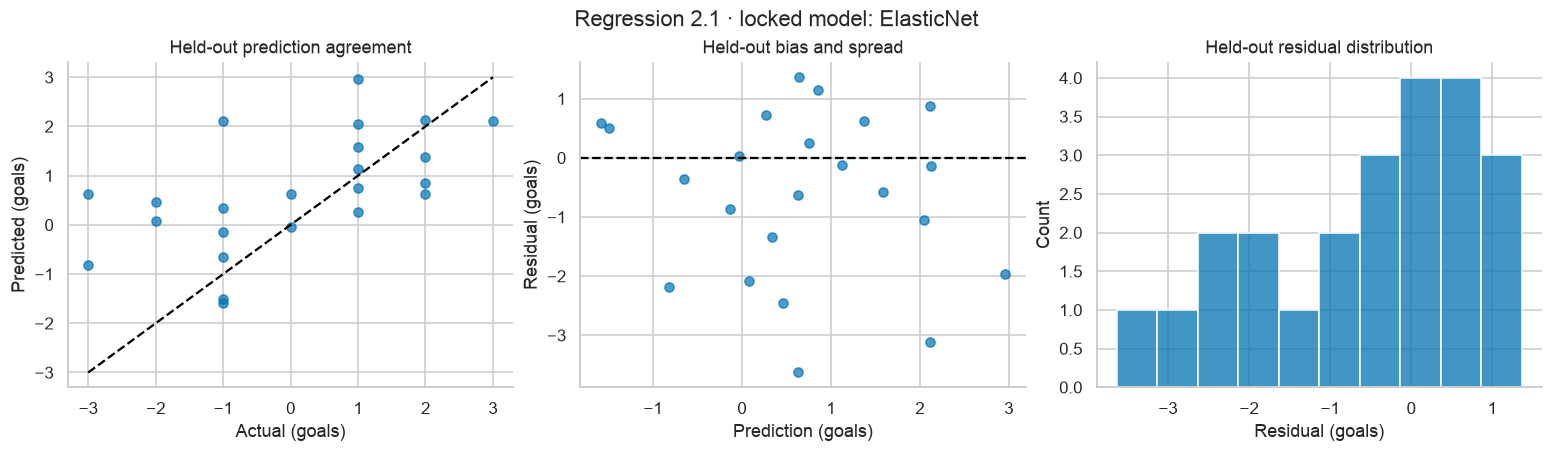

**Final reading:** MAE 1.158 and RMSE 1.503 goals. Test R²=0.175: the model explains 17.5% of held-out response variation. Mean residual -0.626 goals indicates overprediction on average. The final period is largely later tournament stages, so this also tests a changing team/stage mix.

,Quantity,Estimate,95% bootstrap low,95% bootstrap high
0,Test MAE,1.1576,0.7893,1.556
1,MAE improvement over dummy,0.3035,-0.0484,0.607


**Uncertainty:** positive MAE improvement favours the selected model. An interval spanning zero does not establish a reliable benefit. These intervals resample matches, not teams or tournaments, so broader generalisation uncertainty is larger than represented here.

,CV_MAE,CV_RMSE,CV_RMSE_SD,CV_NRMSE,CV_NRMSE_SD,CV_R2,CV_MAE_SD,CV_R2_SD,Outer_train_RMSE,Default CV RMSE,Test MAE,Test MSE,Test RMSE,Test NRMSE,Test NRMSE (%),Test R2,Full train RMSE
Model,,,,,,,,,,,,,,,,,
Ridge,0.8407,1.0258,0.2686,0.2377,0.0178,0.2920,0.2115,0.0081,1.2643,1.0265,0.9200,1.5030,1.2260,0.2043,20.4325,0.1304,1.1809
Linear Regression,0.8458,1.0277,0.2577,0.2382,0.0107,0.2861,0.2107,0.0491,1.2386,1.0277,0.9201,1.5120,1.2296,0.2049,20.4938,0.1251,1.1800
ElasticNet,0.8893,1.0764,0.3159,0.2475,0.0177,0.2304,0.2486,0.0566,1.3002,1.0171,0.9242,1.4969,1.2235,0.2039,20.3914,0.1339,1.1830
Lasso,0.9914,1.1773,0.3976,0.2680,0.0287,0.0925,0.3338,0.1623,1.3891,1.0258,0.9179,1.5082,1.2281,0.2047,20.4684,0.1273,1.1810
Dummy,1.0344,1.2212,0.3245,0.2827,0.0206,-0.0016,0.2624,0.0013,1.4685,1.2212,1.0631,1.7289,1.3149,0.2191,21.9144,-0.0004,1.4107


,match_number,date,team,opponent,Actual,Predicted,Residual
162,81,2026-07-02,USA,Bosnia and Herzegovina,2,2.9999,-0.9999
163,81,2026-07-02,Bosnia and Herzegovina,USA,0,0.6796,-0.6796
164,83,2026-07-02,Portugal,Croatia,2,1.9807,0.0193
165,83,2026-07-02,Croatia,Portugal,1,1.1676,-0.1676
166,84,2026-07-02,Spain,Austria,3,2.4032,0.5968
167,84,2026-07-02,Austria,Spain,0,0.9718,-0.9718
168,85,2026-07-03,Switzerland,Algeria,2,1.8206,0.1794
169,85,2026-07-03,Algeria,Switzerland,0,1.1655,-1.1655
170,86,2026-07-03,Argentina,Cabo Verde,3,2.6786,0.3214
171,86,2026-07-03,Cabo Verde,Argentina,2,0.1608,1.8392


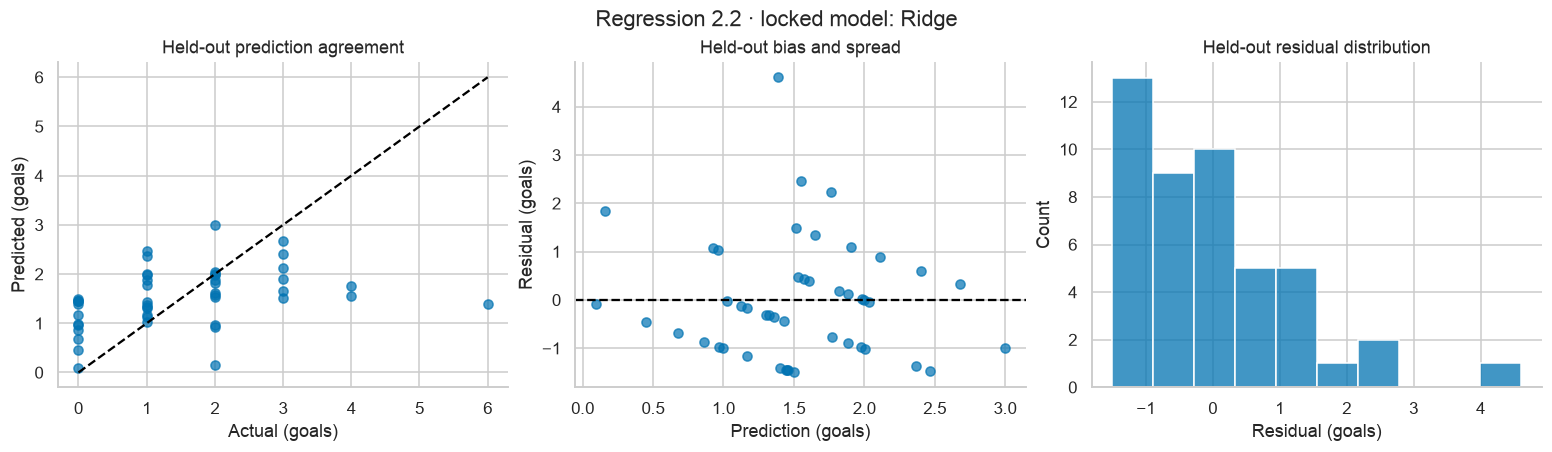

**Final reading:** MAE 0.920 and RMSE 1.226 goals. Test R²=0.130: the model explains 13.0% of held-out response variation. Mean residual -0.025 goals indicates overprediction on average. The final period is largely later tournament stages, so this also tests a changing team/stage mix.

Negative predictions by candidate: {'Dummy': 0, 'Linear Regression': 0, 'Ridge': 0, 'Lasso': 0, 'ElasticNet': 0}


,Quantity,Estimate,95% bootstrap low,95% bootstrap high
0,Test MAE,0.9200,0.6709,1.2395
1,MAE improvement over dummy,0.1431,0.0352,0.2454


**Uncertainty:** positive MAE improvement favours the selected model. An interval spanning zero does not establish a reliable benefit. These intervals resample matches, not teams or tournaments, so broader generalisation uncertainty is larger than represented here.

In [17]:
def final_evaluation(result,test,label):
    assert result['locked']
    fs,target=result['fs'],result['target']
    rows=[];predictions={}
    for name,model in result['fitted'].items():
        predictions[name]=model.predict(test[fs])
        tr=result['train']
        rows.append({'Model':name,**{'Test '+k:v for k,v in metrics(test[target],predictions[name]).items()},
                     'Full train RMSE':metrics(tr[target],model.predict(tr[fs]))['RMSE']})
    table=result['comparison'].join(pd.DataFrame(rows).set_index('Model'))
    display(table)
    name=result['winner'];pred=predictions[name];y=test[target].to_numpy();res=y-pred
    examples=test[['match_number','date']+[c for c in ['team1','team2','team','opponent'] if c in test]].copy()
    examples['Actual']=y;examples['Predicted']=pred;examples['Residual']=res
    display(examples.head(12))
    fig,axes=plt.subplots(1,3,figsize=(14,4))
    axes[0].scatter(y,pred,alpha=.7)
    low,high=min(y.min(),pred.min()),max(y.max(),pred.max())
    axes[0].plot([low,high],[low,high],color='black',ls='--')
    axes[0].set(xlabel='Actual (goals)',ylabel='Predicted (goals)',title='Held-out prediction agreement')
    axes[1].scatter(pred,res,alpha=.7);axes[1].axhline(0,color='black',ls='--')
    axes[1].set(xlabel='Prediction (goals)',ylabel='Residual (goals)',title='Held-out bias and spread')
    sns.histplot(res,bins=10,ax=axes[2]);axes[2].set(xlabel='Residual (goals)',title='Held-out residual distribution')
    fig.suptitle(f'{label} · locked model: {name}');plt.show()
    if result['best_linear'] != name:
        linear_name=result['best_linear'];linear_pred=predictions[linear_name]
        linear_res=y-linear_pred
        regression_examples=examples.copy()
        regression_examples['Predicted']=linear_pred
        regression_examples['Residual']=linear_res
        display(Markdown(f'**Required regression output: {linear_name}**, selected among linear families by CV.'))
        display(regression_examples.head(12))
        fig,axes=plt.subplots(1,3,figsize=(14,4))
        axes[0].scatter(y,linear_pred,alpha=.7)
        low,high=min(y.min(),linear_pred.min()),max(y.max(),linear_pred.max())
        axes[0].plot([low,high],[low,high],color='black',ls='--')
        axes[0].set(xlabel='Actual team goals',ylabel='Predicted team goals',title='Selected linear family')
        axes[1].scatter(linear_pred,linear_res,alpha=.7)
        axes[1].axhline(0,color='black',ls='--')
        axes[1].set(xlabel='Predicted team goals',ylabel='Residual (goals)',title='Linear model residuals')
        sns.histplot(linear_res,bins=10,ax=axes[2])
        axes[2].set(xlabel='Residual (goals)',title='Linear model residual distribution')
        fig.suptitle(f'{label} · {linear_name}: regression analysis retained');plt.show()
        linear_score=metrics(y,linear_pred)
        display(Markdown(f"**Linear-model interpretation:** {linear_name} has test MAE {linear_score['MAE']:.3f}, "
                        f"MSE {linear_score['MSE']:.3f}, RMSE {linear_score['RMSE']:.3f} and R² {linear_score['R2']:.3f}. "
                        'It improves on the dummy in this final block, but did not beat it across the nested temporal folds. '
                        'The locked baseline recommendation is retained; this disagreement limits confidence in generalisation.'))
    scores=metrics(y,pred)
    r2_text=(f"explains {100*scores['R2']:.1f}% of held-out response variation" if scores['R2']>=0 else
             'has larger squared error than the held-out sample-mean reference')
    display(Markdown(f"**Final reading:** MAE {scores['MAE']:.3f} and RMSE {scores['RMSE']:.3f} goals. "
                    f"Test R²={scores['R2']:.3f}: the model {r2_text}. "
                    f"Mean residual {res.mean():+.3f} goals indicates {'underprediction' if res.mean()>0 else 'overprediction'} on average. "
                    'The final period is largely later tournament stages, so this also tests a changing team/stage mix.'))
    if target=='goals_scored':
        print('Negative predictions by candidate:',{k:int((p<0).sum()) for k,p in predictions.items()})
    rng=np.random.default_rng(RANDOM_STATE)
    groups=test.match_number.to_numpy();ids=np.unique(groups)
    boot=[]
    for _ in range(2000):
        sample=rng.choice(ids,size=len(ids),replace=True)
        ix=np.concatenate([np.flatnonzero(groups==m) for m in sample])
        mae=mean_absolute_error(y[ix],pred[ix])
        gain=mean_absolute_error(y[ix],predictions['Dummy'][ix])-mae
        boot.append([mae,gain])
    intervals=np.quantile(boot,[.025,.975],axis=0)
    uncertainty=pd.DataFrame({'Quantity':['Test MAE','MAE improvement over dummy'],
                               'Estimate':[scores['MAE'],metrics(y,predictions['Dummy'])['MAE']-scores['MAE']],
                               '95% bootstrap low':intervals[0],'95% bootstrap high':intervals[1]})
    display(uncertainty)
    display(Markdown('**Uncertainty:** positive MAE improvement favours the selected model. An interval spanning zero '
                    'does not establish a reliable benefit. These intervals resample matches, not teams or tournaments, '
                    'so broader generalisation uncertainty is larger than represented here.'))
    result.update(test=test,test_table=table,predictions=predictions,test_scores=scores,uncertainty=uncertainty)
final_evaluation(result21,test21,'Regression 2.1')
final_evaluation(result22,test22,'Regression 2.2')

### 16.1. Course error calculations · Both regression tasks
The first table collects held-out MAE, MSE, RMSE, NRMSE and R² for every candidate, including the mean baseline. The second shows the course adjusted-R² calculation for the required training OLS models. These calculations reuse the existing predictions; they do not change model selection.

A worked calculation for each CV-selected linear family follows: residuals, absolute errors and squared errors are shown alongside the resulting averages and normalised RMSE.

In [18]:
course_tables = []
ols_fit_rows = []
for task, result in [('2.1', result21), ('2.2', result22)]:
    selected_columns = ['Test MAE', 'Test MSE', 'Test RMSE', 'Test NRMSE', 'Test NRMSE (%)', 'Test R2']
    table = result['test_table'][selected_columns].reset_index()
    table.insert(0, 'Task', task)
    table['Role'] = table['Model'].map(lambda name: 'CV recommendation' if name == result['winner']
                                     else ('CV-selected linear family' if name == result['best_linear'] else 'Comparator'))
    course_tables.append(table)
    ols = result['ols']
    observations, predictors = int(ols.nobs), len(result['fs'])
    assert observations > predictors + 1
    assert np.linalg.matrix_rank(ols.model.exog) == predictors + 1
    adjusted_r2 = 1 - (1 - ols.rsquared) * (observations - 1) / (observations - predictors - 1)
    assert np.isclose(adjusted_r2, ols.rsquared_adj)
    ols_fit_rows.append({'Task': task, 'Model': 'Training OLS', 'n': observations,
                         'p (excluding intercept)': predictors, 'Training R2': ols.rsquared,
                         'Training adjusted R2': adjusted_r2})
course_metrics_table = pd.concat(course_tables, ignore_index=True)
display(course_metrics_table)
display(pd.DataFrame(ols_fit_rows))

for task, result in [('2.1', result21), ('2.2', result22)]:
    name = result['best_linear']
    actual = result['test'][result['target']].to_numpy(dtype=float)
    predicted = result['predictions'][name]
    residual = actual - predicted
    worked = pd.DataFrame({'Actual': actual, 'Predicted': predicted, 'Residual': residual,
                           'Absolute error': np.abs(residual), 'Squared error': residual ** 2})
    score = metrics(actual, predicted)
    denominator = actual.max() - actual.min()
    assert denominator > 0, 'NRMSE is undefined for a constant test target.'
    assert np.isclose(worked['Absolute error'].mean(), score['MAE'])
    assert np.isclose(worked['Squared error'].mean(), score['MSE'])
    assert np.isclose(np.sqrt(score['MSE']), score['RMSE'])
    assert np.isclose(score['RMSE'] / denominator, score['NRMSE'])
    assert np.isclose(1 - np.sum(residual**2) / np.sum((actual-actual.mean())**2), score['R2'])
    display(Markdown(f'**Task {task}: {name} — first eight test observations**'))
    display(worked.head(8))
    display(Markdown(
        f"Using all **{len(actual)}** test observations: MAE = **{score['MAE']:.4f} goals**; "
        f"MSE = **{score['MSE']:.4f} goals²**; RMSE = √{score['MSE']:.4f} = **{score['RMSE']:.4f} goals**. "
        f"The actual target range is {actual.max():g} − ({actual.min():g}) = **{denominator:g} goals**. "
        f"NRMSE = {score['RMSE']:.4f} / {denominator:g} = **{score['NRMSE']:.4f} "
        f"({score['NRMSE (%)']:.2f}%)**. This is error as a percentage of the observed range, not accuracy. "
        f"Held-out R² = **{score['R2']:.4f}**."))
print('PASS: manual course formulas agree with the model metrics and statsmodels adjusted R².')


,Task,Model,Test MAE,Test MSE,Test RMSE,Test NRMSE,Test NRMSE (%),Test R2,Role
0,2.1,ElasticNet,1.1576,2.2589,1.5030,0.2505,25.0495,0.1747,CV recommendation
1,2.1,Ridge,1.1516,2.2254,1.4918,0.2486,24.8628,0.1870,Comparator
2,2.1,Linear Regression,1.1761,2.2449,1.4983,0.2497,24.9714,0.1799,Comparator
3,2.1,Lasso,1.1534,2.2337,1.4945,0.2491,24.9090,0.1840,Comparator
4,2.1,Dummy,1.4611,3.0525,1.7471,0.2912,29.1189,-0.1152,Comparator
5,2.2,Ridge,0.9200,1.5030,1.2260,0.2043,20.4325,0.1304,CV recommendation
6,2.2,Linear Regression,0.9201,1.5120,1.2296,0.2049,20.4938,0.1251,Comparator
7,2.2,ElasticNet,0.9242,1.4969,1.2235,0.2039,20.3914,0.1339,Comparator
8,2.2,Lasso,0.9179,1.5082,1.2281,0.2047,20.4684,0.1273,Comparator
9,2.2,Dummy,1.0631,1.7289,1.3149,0.2191,21.9144,-0.0004,Comparator


,Task,Model,n,p (excluding intercept),Training R2,Training adjusted R2
0,2.1,Training OLS,81,8,0.5336,0.4818
1,2.2,Training OLS,162,8,0.3003,0.2638


**Task 2.1: ElasticNet — first eight test observations**

,Actual,Predicted,Residual,Absolute error,Squared error
0,2.0,2.1310,-0.1310,0.1310,0.0172
1,1.0,0.7572,0.2428,0.2428,0.0589
2,3.0,2.1169,0.8831,0.8831,0.7799
3,2.0,0.6376,1.3624,1.3624,1.8562
4,1.0,2.9615,-1.9615,1.9615,3.8475
5,0.0,0.6329,-0.6329,0.6329,0.4005
6,1.0,1.5856,-0.5856,0.5856,0.3429
7,-1.0,-1.4983,0.4983,0.4983,0.2483


Using all **23** test observations: MAE = **1.1576 goals**; MSE = **2.2589 goals²**; RMSE = √2.2589 = **1.5030 goals**. The actual target range is 3 − (-3) = **6 goals**. NRMSE = 1.5030 / 6 = **0.2505 (25.05%)**. This is error as a percentage of the observed range, not accuracy. Held-out R² = **0.1747**.

**Task 2.2: Ridge — first eight test observations**

,Actual,Predicted,Residual,Absolute error,Squared error
0,2.0,2.9999,-0.9999,0.9999,0.9997
1,0.0,0.6796,-0.6796,0.6796,0.4619
2,2.0,1.9807,0.0193,0.0193,0.0004
3,1.0,1.1676,-0.1676,0.1676,0.0281
4,3.0,2.4032,0.5968,0.5968,0.3562
5,0.0,0.9718,-0.9718,0.9718,0.9445
6,2.0,1.8206,0.1794,0.1794,0.0322
7,0.0,1.1655,-1.1655,1.1655,1.3584


Using all **46** test observations: MAE = **0.9200 goals**; MSE = **1.5030 goals²**; RMSE = √1.5030 = **1.2260 goals**. The actual target range is 6 − (0) = **6 goals**. NRMSE = 1.2260 / 6 = **0.2043 (20.43%)**. This is error as a percentage of the observed range, not accuracy. Held-out R² = **0.1304**.

PASS: manual course formulas agree with the model metrics and statsmodels adjusted R².


## 17. Final linear-model interpretation and coefficient uncertainty
For each task, the best CV linear family is interpreted even if the dummy is the overall recommendation. A one-unit change in a standardised predictor means one **training SD** in its original scale, holding all other inputs fixed. The intercept is the prediction at training means after imputation. Raw-unit coefficients are also provided.

The OLS robust confidence intervals from Sections 9/14 quantify uncertainty in mean associations under covariance assumptions. They are **not** valid intervals for penalised coefficients. A prediction interval would describe a future individual outcome and be wider; classical normal-theory OLS intervals are omitted because discrete outcomes, changing stages and repeated teams make nominal coverage doubtful. No unsupported uncertainty interval is attached to penalised predictions.

,Feature,Coefficient per training SD,Absolute coefficient,Coefficient per raw unit,Direction,Meaning,Interpretation
0,fifa_points_diff,0.9301,0.9301,0.0039,Positive,Team1 minus team2 pre-tournament FIFA ranking points (11 June 2026),"+0.930 predicted goals per +1 training SD, other inputs fixed"
7,prev_xg_against_diff,-0.4751,0.4751,-0.6000,Negative,Difference in prior centred expected goals conceded per match,"-0.475 predicted goals per +1 training SD, other inputs fixed"
1,wc_experience_diff,0.2597,0.2597,0.0059,Positive,Difference in World Cup matches played before 2026,"+0.260 predicted goals per +1 training SD, other inputs fixed"
6,prev_xg_diff,-0.2056,0.2056,-0.2511,Negative,Difference in prior centred expected goals per match,"-0.206 predicted goals per +1 training SD, other inputs fixed"
2,host_advantage,0.1781,0.1781,0.5119,Positive,Team1 home-country indicator minus team2 indicator,"+0.178 predicted goals per +1 training SD, other inputs fixed"
3,strong_confederation_diff,0.0213,0.0213,0.0272,Positive,Team1 minus team2 UEFA/CONMEBOL membership indicator,"+0.021 predicted goals per +1 training SD, other inputs fixed"
4,prev_goals_against_diff,-0.0000,0.0000,-0.0000,Zero,Difference in prior centred goals conceded per match,"-0.000 predicted goals per +1 training SD, other inputs fixed"
5,prev_shots_diff,0.0000,0.0000,0.0000,Zero,Difference in prior centred shots per match,"+0.000 predicted goals per +1 training SD, other inputs fixed"


Selected linear model: ElasticNet | Standardised intercept: 0.6049382716049383
Raw-unit intercept: 0.23896600042466548


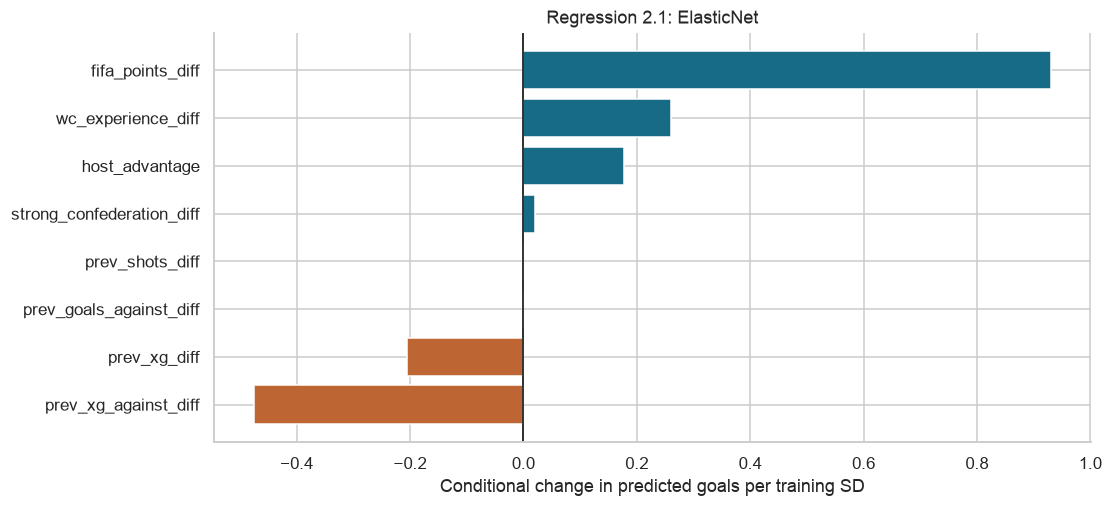

**Interpretation:** strongest positive association: ['fifa_points_diff']; strongest negative association: ['prev_xg_against_diff']. Smallest coefficient magnitudes: ['prev_goals_against_diff', 'prev_shots_diff']. Strength, scoring history and opponent defence have plausible football links, but signs can reverse when correlated inputs are conditioned upon. Large coefficients do not guarantee out-of-sample importance; small penalised coefficients can represent redundancy rather than an irrelevant football concept.

,Feature,Coefficient per training SD,Absolute coefficient,Coefficient per raw unit,Direction,Meaning,Interpretation
1,opponent_fifa_rank,0.3950,0.3950,0.0172,Positive,Pre-tournament FIFA ranking of opponent (lower is better),"+0.395 predicted goals per +1 training SD, other inputs fixed"
0,team_fifa_rank,-0.2565,0.2565,-0.0111,Negative,Pre-tournament FIFA ranking of scoring team (lower is better),"-0.257 predicted goals per +1 training SD, other inputs fixed"
5,team_prev_linebreaks,0.2430,0.2430,0.0101,Positive,Team prior centred completed line breaks per match,"+0.243 predicted goals per +1 training SD, other inputs fixed"
6,team_is_host,0.1631,0.1631,0.6779,Positive,1 if the scoring team plays in its own country,"+0.163 predicted goals per +1 training SD, other inputs fixed"
2,team_strong_confederation,0.1159,0.1159,0.2322,Positive,1 if the scoring team belongs to UEFA or CONMEBOL,"+0.116 predicted goals per +1 training SD, other inputs fixed"
7,opponent_prev_xg_against,0.1133,0.1133,0.1804,Positive,Opponent prior centred expected goals conceded per match,"+0.113 predicted goals per +1 training SD, other inputs fixed"
4,team_prev_possession,-0.0237,0.0237,-0.2596,Negative,Team prior centred possession fraction,"-0.024 predicted goals per +1 training SD, other inputs fixed"
3,opponent_strong_confederation,0.0050,0.0050,0.0100,Positive,1 if the opponent belongs to UEFA or CONMEBOL,"+0.005 predicted goals per +1 training SD, other inputs fixed"


Selected linear model: Ridge | Standardised intercept: 1.4753086419753085
Raw-unit intercept: 1.1314712542449663


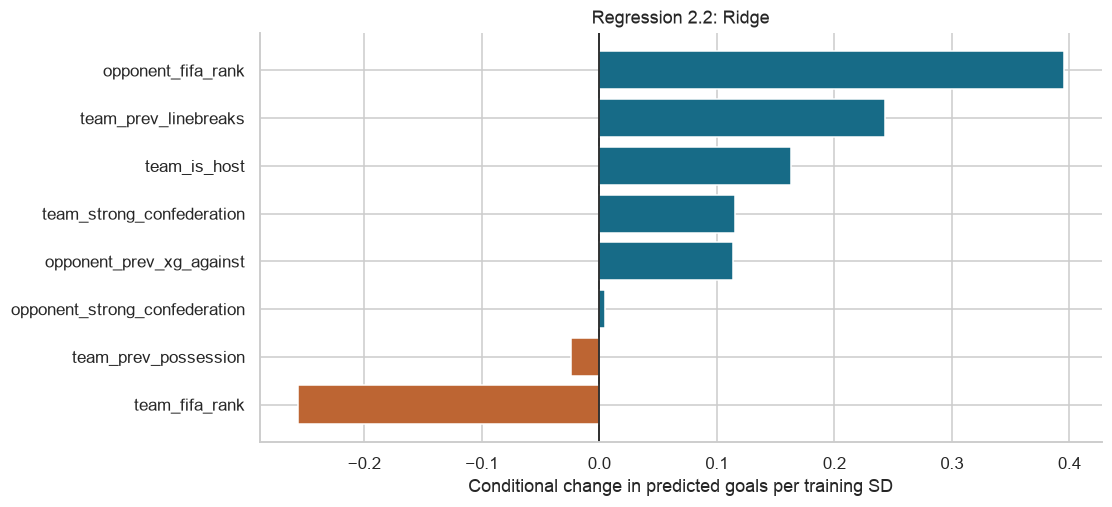

**Interpretation:** strongest positive association: ['opponent_fifa_rank']; strongest negative association: ['team_fifa_rank']. Smallest coefficient magnitudes: ['team_prev_possession', 'opponent_strong_confederation']. Strength, scoring history and opponent defence have plausible football links, but signs can reverse when correlated inputs are conditioned upon. Large coefficients do not guarantee out-of-sample importance; small penalised coefficients can represent redundancy rather than an irrelevant football concept.

In [19]:
def explain_linear(result,label):
    name=result['best_linear'];model=result['fitted'][name];fs=result['fs']
    coef=model['model'].coef_;scaler=model['scale']
    table=pd.DataFrame({'Feature':fs,'Coefficient per training SD':coef,'Absolute coefficient':abs(coef),
                        'Coefficient per raw unit':coef/scaler.scale_,
                        'Direction':np.where(coef>0,'Positive',np.where(coef<0,'Negative','Zero')),
                        'Meaning':[meanings[f] for f in fs]})
    table['Interpretation']=[f'{c:+.3f} predicted goals per +1 training SD, other inputs fixed' for c in coef]
    table=table.sort_values('Absolute coefficient',ascending=False);display(table)
    print('Selected linear model:',name,'| Standardised intercept:',model['model'].intercept_)
    print('Raw-unit intercept:',model['model'].intercept_-np.sum(coef*scaler.mean_/scaler.scale_))
    plot=table.sort_values('Coefficient per training SD')
    fig,ax=plt.subplots(figsize=(10,4.5))
    ax.barh(plot.Feature,plot['Coefficient per training SD'],
            color=np.where(plot['Coefficient per training SD']>=0,'#176b87','#bd6533'))
    ax.axvline(0,color='black',lw=1);ax.set(xlabel='Conditional change in predicted goals per training SD',title=f'{label}: {name}')
    plt.show()
    positive=table.loc[table['Coefficient per training SD']>0].head(1).Feature.tolist()
    negative=table.loc[table['Coefficient per training SD']<0].head(1).Feature.tolist()
    weak=table.tail(2).Feature.tolist()
    display(Markdown(f'**Interpretation:** strongest positive association: {positive or "none"}; '
                    f'strongest negative association: {negative or "none"}. Smallest coefficient magnitudes: {weak}. '
                    'Strength, scoring history and opponent defence have plausible football links, but signs can reverse '
                    'when correlated inputs are conditioned upon. Large coefficients do not guarantee out-of-sample importance; '
                    'small penalised coefficients can represent redundancy rather than an irrelevant football concept.'))
    result['coefficients']=table
explain_linear(result21,'Regression 2.1')
explain_linear(result22,'Regression 2.2')

## 18. Scientific recommendations and cross-task comparison
Absolute errors have goal units for both tasks, but the distributions of signed goal difference and team goals differ. Compare baseline-relative improvement and held-out $R^2$ alongside RMSE; a smaller raw RMSE does not alone establish an easier scientific problem. The same test matches make the setting comparable, while row dependence and training samples still differ.

### Task 2.1: recommendation
**ElasticNet** is the CV-selected prediction model; **ElasticNet** is the selected regression family. Held-out RMSE is 1.503 versus 1.747 goals for the dummy (+14.0% improvement). For the selected linear family, tuning changes outer mean RMSE from 1.315 to 1.414 (+0.099 goals). Optimisation does not consistently improve outer-CV performance here; the default scores are diagnostic comparators, while the predeclared primary competition compares the tuning procedures. The evidence for practical use must include the uncertainty interval and the training–validation gap, not the test ranking of other candidates. The largest conditional linear coefficient is `fifa_points_diff`. Linearity and variance diagnostics are approximate; independence is not established because teams repeat. Use this as a tournament-specific analytical benchmark. Strong deployment claims require verified source provenance and evaluation on new tournaments; forecasts are expected values, not guaranteed scores.

### Task 2.2: recommendation
**Ridge** is the CV-selected prediction model; **Ridge** is the selected regression family. Held-out RMSE is 1.226 versus 1.315 goals for the dummy (+6.8% improvement). For the selected linear family, tuning changes outer mean RMSE from 1.027 to 1.026 (-0.001 goals). Optimisation does not consistently improve outer-CV performance here; the default scores are diagnostic comparators, while the predeclared primary competition compares the tuning procedures. The evidence for practical use must include the uncertainty interval and the training–validation gap, not the test ranking of other candidates. The largest conditional linear coefficient is `opponent_fifa_rank`. Linearity and variance diagnostics are approximate; independence is not established because teams repeat. Use this as a tournament-specific analytical benchmark. Strong deployment claims require verified source provenance and evaluation on new tournaments; forecasts are expected values, not guaranteed scores.

,Locked recommendation,Best linear family,Test RMSE,Test R²,Test RMSE improvement over dummy (%),CV RMSE improvement over dummy (%)
Task,,,,,,
2.1,ElasticNet,ElasticNet,1.503,0.1747,13.9750,26.4082
2.2,Ridge,Ridge,1.226,0.1304,6.7622,15.9998


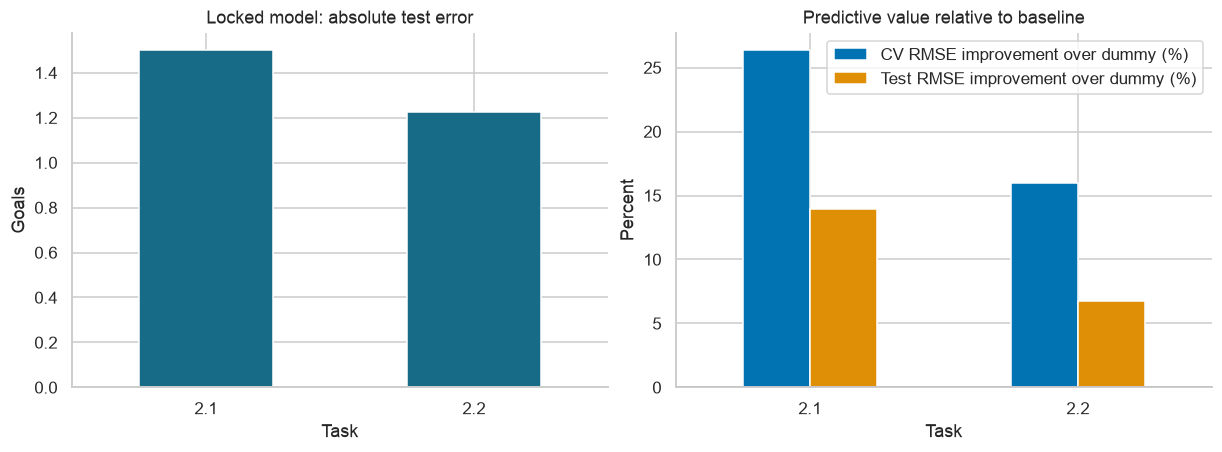

**Across tasks:** task 2.1 has the larger held-out R² in this sample. This is descriptive evidence, not a significance test of which target is universally easier. Goal difference mixes both attacks and defences; team goals isolate one attack but still depend on the opponent. Late-stage selection, sparse prior histories and unpredictable scoring events can leave substantial variation unexplained. Disagreement between CV and test gains is evidence of uncertainty or distribution change, rather than a reason to retune on test data.

In [20]:
findings=[]
for label,r in [('2.1',result21),('2.2',result22)]:
    winner=r['winner'];linear=r['best_linear'];table=r['test_table'];comp=r['comparison']
    base=table.loc['Dummy','Test RMSE'];selected=table.loc[winner,'Test RMSE']
    gain=100*(base-selected)/base
    default=comp.loc[linear,'Default CV RMSE'];tuned=comp.loc[linear,'CV_RMSE']
    findings.append({'Task':label,'Locked recommendation':winner,'Best linear family':linear,
                     'Test RMSE':selected,'Test R²':r['test_scores']['R2'],
                     'Test RMSE improvement over dummy (%)':gain,
                     'CV RMSE improvement over dummy (%)':100*(comp.loc['Dummy','CV_RMSE']-comp.loc[winner,'CV_RMSE'])/comp.loc['Dummy','CV_RMSE']})
    display(Markdown(f"### Task {label}: recommendation\n**{winner}** is the CV-selected prediction model; "
                    f"**{linear}** is the selected regression family. Held-out RMSE is {selected:.3f} versus "
                    f"{base:.3f} goals for the dummy ({gain:+.1f}% improvement). "
                    f"For the selected linear family, tuning changes outer mean RMSE from {default:.3f} to {tuned:.3f} "
                    f"({tuned-default:+.3f} goals). "
                    'Optimisation does not consistently improve outer-CV performance here; the default scores are diagnostic comparators, '
                    'while the predeclared primary competition compares the tuning procedures. '
                    'The evidence for practical use must include the uncertainty interval and the training–validation gap, '
                    'not the test ranking of other candidates. '
                    f"The largest conditional linear coefficient is `{r['coefficients'].iloc[0].Feature}`. "
                    'Linearity and variance diagnostics are approximate; independence is not established because teams repeat. '
                    'Use this as a tournament-specific analytical benchmark. Strong deployment claims require verified source provenance '
                    'and evaluation on new tournaments; forecasts are expected values, not guaranteed scores.'))
comparison=pd.DataFrame(findings).set_index('Task');display(comparison)
fig,axes=plt.subplots(1,2,figsize=(11,4))
comparison[['Test RMSE']].plot.bar(ax=axes[0],legend=False,color='#176b87',rot=0)
axes[0].set(ylabel='Goals',title='Locked model: absolute test error')
comparison[['CV RMSE improvement over dummy (%)','Test RMSE improvement over dummy (%)']].plot.bar(ax=axes[1],rot=0)
axes[1].axhline(0,color='black',lw=1);axes[1].set(ylabel='Percent',title='Predictive value relative to baseline')
plt.show()
easiest=comparison['Test R²'].idxmax()
display(Markdown(f'**Across tasks:** task {easiest} has the larger held-out R² in this sample. '
                'This is descriptive evidence, not a significance test of which target is universally easier. '
                'Goal difference mixes both attacks and defences; team goals isolate one attack but still depend on the opponent. '
                'Late-stage selection, sparse prior histories and unpredictable scoring events can leave substantial variation unexplained. '
                'Disagreement between CV and test gains is evidence of uncertainty or distribution change, rather than a reason to retune on test data.'))

## 19. Limitations and next steps
1. **Data provenance.** All 104 scores agree with an independent source, but some match dates differ by one day between the sources and the files hold no kickoff times. The ranking values rely on the 11 June 2026 date recorded in Part 1. No data were corrected by hand.
2. **Small, dependent sample.** There are 104 matches, not 208 independent matches. Repeated teams violate simple independent-error assumptions even with match clustering. Three expanding windows have different sample sizes and stages.
3. **Prior data exposure.** The exploratory Part 3 and Part 4 notebooks already used these outcomes, and five variables here were replaced after training-fold screening. The temporal evaluation limits the optimism this causes, but the test set is not a truly untouched sample.
4. **History quality.** Tournament-only historical averages are noisy for teams with few matches, assume earlier statistics were published before prediction time, and use neutral zero priors in centred units. Rest is capped at ten days by specification. Exact kickoff times are unavailable, so all same-day information is excluded.
5. **Distribution change.** The final date block contains later-stage, selected teams; generalisation to early group matches, another tournament or unfamiliar teams is untested. These are sequential pre-match forecasts, not June-start tournament predictions.
6. **Model assumptions.** Goal counts are discrete and bounded below; linear outputs need not be. Signed differences are also discrete. Uncertainty in outcomes, injuries, lineups, tactical changes and red cards cannot be eliminated with eight predictors. Observational coefficients are not causal effects.
7. **Model search uncertainty.** Nested CV limits tuning optimism, but selecting a family from three outer mean scores still incurs selection uncertainty. Hyperparameter grids are intentionally modest; the test set never determines grid expansion.

**Next steps:** record kickoff times, preserve a new prospective test tournament, timestamp pre-match data snapshots, evaluate team-aware uncertainty and calibrated count forecasts, and compare any extensions using the same predeclared forecast timing. These steps strengthen scientific validity without concealing weak results.

## 20. Automated compliance and reproducibility checklist
PASS means checked from the current run, not promised by a filename. Feature counts and overlap raise an error if invalid. Modelling flags below require actual fitted objects, diagnostic outputs and held-out predictions. EDA and methodological discussion also require human review; their presence is not a machine certification of quality.


In [21]:
assert len(d21)==104 and len(d22)==208
assert len(features_21)==8 and len(features_22)==8
shared_features=set(features_21).intersection(features_22)
assert len(shared_features)<=4 and len(shared_families)<=4
checks=[]
def check(name,ok,detail=''):
    checks.append([name,'PASS' if bool(ok) else 'FAIL',detail])
for label,df,fs,target,r,n in [('2.1',d21,features_21,'goal_difference',result21,104),
                              ('2.2',d22,features_22,'goals_scored',result22,208)]:
    check(label+' observation count',len(df)==n,str(len(df)))
    check(label+' eight predictors',len(fs)==8,', '.join(fs))
    check(label+' target',target in df,target)
    check(label+' current/future outcome exclusion',all(x['Current/future changes leave prior predictors unchanged'] for x in mutation_checks))
    check(label+' pre-match ranking only',not any('post' in c for c in fs),'11 June 2026 ranking; post-tournament columns unused')
    check(label+' final dataset saved',(ROOT/'Dataset'/('regression_2_1_goal_difference.csv' if label=='2.1' else 'regression_2_2_team_goals.csv')).exists())
    check(label+' missing data handled',all('impute' in m.named_steps for m in r['fitted'].values()))
    check(label+' leakage audit complete',len(leakage_audit(fs))==8)
    check(label+' VIF and assumptions evaluated',len(r['vif'])==8 and len(r['influence'])==len(r['train']))
    check(label+' OLS fitted',len(r['ols'].params)==9)
    check(label+' chronological CV',len(r['folds'])==15)
    check(label+' competing algorithms',len(r['fitted'])==5)
    check(label+' optimisation',len(r['search'])==3)
    check(label+' baseline comparison','Dummy' in r['test_table'].index)
    check(label+' final test evaluation',all(len(p)==len(r['test']) and np.isfinite(p).all() for p in r['predictions'].values()))
    check(label+' model interpretation',len(r['coefficients'])==8)
    check(label+' sensitivity',len(r['sensitivity'])==4)
    check(label+' whole-match holdout',set(r['train'].match_number).isdisjoint(r['test'].match_number))
check('Course metrics calculated and verified', len(course_metrics_table)==10 and np.isfinite(course_metrics_table[['Test MAE','Test MSE','Test RMSE','Test NRMSE','Test R2']].to_numpy()).all(), 'Section 16.1: manual formulas checked; training OLS adjusted R² verified')
check('Cross-task overlap',len(shared_features)<=4 and len(shared_families)<=4,
      f'Literal: {len(shared_features)}; conservative families: {len(shared_families)}')
check('Source-to-candidate reconstruction',True,'Assertions executed in Section 4')
check('Independent score cross-check',source_checks['Scores agree'].all(),
      f"{agree}/104 scores agree; {104-same_day} dates differ by one day")
checks.extend([['EDA and visual interpretations','REVIEW','Sections 7 and 12; rendered outputs'],
               ['Limitations and recommendations','REVIEW','Sections 18–19'],
               ['Reproducible environment','PASS','Versions, seed, archive hash and deterministic date splits recorded']])
checklist=pd.DataFrame(checks,columns=['Requirement','Status','Evidence']);display(checklist)
print('Feature assertions: PASS')
print('Automated checks failed:', int(checklist.Status.eq('FAIL').sum()), 'of', int(checklist.Status.isin(['PASS','FAIL']).sum()))

,Requirement,Status,Evidence
0,2.1 observation count,PASS,104
1,2.1 eight predictors,PASS,"fifa_points_diff, wc_experience_diff, host_advantage, strong_confederation_diff, prev_goals_against_diff, prev_shots..."
2,2.1 target,PASS,goal_difference
3,2.1 current/future outcome exclusion,PASS,
4,2.1 pre-match ranking only,PASS,11 June 2026 ranking; post-tournament columns unused
5,2.1 final dataset saved,PASS,
6,2.1 missing data handled,PASS,
7,2.1 leakage audit complete,PASS,
8,2.1 VIF and assumptions evaluated,PASS,
9,2.1 OLS fitted,PASS,


Feature assertions: PASS
Automated checks failed: 0 of 41
